# Track C: Raster CV floor-plan parser (U-Net segmentation → walls, rooms, doors, adjacency)

**CV5570 · Team Visionaries · Track C** — the third route to the same manifest:

| Track | Input | Method | Role |
|---|---|---|---|
| A | DXF entities | classical geometry (done) | **benchmark** |
| B | vector primitives → graph | GNN (Phases A/B done) | learned, vector |
| **C** | **pixels only** | **U-Net semantic segmentation + raster post-processing** | learned, raster (this notebook) |

Track C never reads layers, blocks or attributes. It looks at a rendered image of the drawing, exactly what a scanned or PDF plan would give, and rebuilds walls, rooms, doors, windows and room adjacency from the pixels.

**Data flow**
1. Phase A FloorPlanCAD graph shards (already on your HF repo) → **rendered** into 10 mm/px images plus pixel masks. No re-download of FloorPlanCAD.
2. U-Net (ResNet-34 encoder, ImageNet weights, 1-channel input) trained for a **fixed time budget** on 2× T4.
3. Test metrics: pixel IoU per class (clean / mild scan / heavy scan) and instance Panoptic Quality for doors, windows, stairs and lifts.
4. TOWER-B DXF → rendered image → segmentation → sealed walls → rooms (holes) → doors with widths → adjacency → **compared against the Track A manifest**.

### Time budget (Kaggle, GPU T4 ×2)
Times marked *est.* are estimates for the real dataset; *measured* are from development runs.

| § | Cell | Time |
|---|---|---|
| 0 | Install packages | ~1–2 min (est.) |
| 1 | Config | instant |
| 2 | Write `rastercv.py` | instant |
| 3 | HF download of shards | ~1–4 min (est., depends on shard size) |
| 4 | Render tiles → PNG masks | ~4–8 min (est.) |
| 5 | Loaders + augmentation preview | ~20 s |
| 6 | Dry run (throughput) | ~1–2 min |
| 7 | **Training** | **`TRAIN_MINUTES` (default 105)** |
| 8 | Test evaluation, 3 degradation levels | ~4–6 min (est.) |
| 9 | TOWER-B render + inference + extraction + comparison | ~4–6 min (est.) |
| 10 | Optional OCR of room labels | ~3–6 min (est.) |
| 11 | Save + push to HF | ~1 min |
| | **Total** | **≈ 2 h 15 min – 2 h 30 min**, leaving ≥ 30 min of slack in a 3-hour window |

### Before you press *Run all*
**Kaggle**
- Settings → Accelerator **GPU T4 ×2**, Internet **on**.
- Add-ons → Secrets → add **`HF_TOKEN`** (write access) and tick it for this notebook.
- TOWER-B files: either attach a Kaggle dataset that holds `TOWER-B GF(1).dxf` and `manifest_TOWER-B_GF.json`, or upload both once to your HF dataset repo under `towerb/`. §9 searches the working dir, then `/kaggle/input`, then HF.

**Colab**: Runtime → T4 GPU, and add `HF_TOKEN` in the 🔑 Secrets panel. With one GPU the same time budget sees about half as many images. The notebook runs unchanged.

Data licence: FloorPlanCAD is CC BY-NC 4.0. Keep the repo private, and push only model weights and metrics, never rendered drawings.

## 0. Install packages · ~1–2 min (est.)
`segmentation_models_pytorch` provides the U-Net, `ezdxf` renders the TOWER-B DXF, `shapely`/`scipy` handle polygons and matching, and `huggingface_hub` handles download and push. PyTorch is preinstalled on Kaggle and Colab.

In [12]:
%pip install -q segmentation-models-pytorch ezdxf shapely huggingface_hub pyarrow

Note: you may need to restart the kernel to use updated packages.


## 1. Config · instant
Every knob lives here. The main ones:
- `TRAIN_MINUTES`: wall-clock training budget. The LR schedule is cosine over **time**, not epochs, so any budget ends with a properly decayed model.
- `BATCH` / `CROP`: 24 random 512² crops per step, split 12 + 12 over the two T4s by `DataParallel`.
- `N_TEST_SHARDS`: the FloorPlanCAD test split is large (~5.5k drawings), so a couple of shards (~500 tiles) give stable metrics in a few minutes.
- `RUN_OCR`: optional room-label OCR on TOWER-B in §10.

`SMOKE=True` shrinks everything to a 2-minute CPU check of the full pipeline.

In [13]:
import os
import sys
import json
import time
import glob
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

HF_REPO_ID = ""
HF_REPO_NAME = "floorplancad-graphs-visionaries"
HF_PUSH_PREFIX = "models/raster"
LOCAL_HF_DIR = os.environ.get("TRACKC_LOCAL_HF")
SMOKE = os.environ.get("TRACKC_SMOKE") == "1"

ON_KAGGLE = Path("/kaggle/working").exists()
WORK = Path("/kaggle/working/trackC") if ON_KAGGLE else Path("trackC_work").resolve()
DATA = WORK / "hf"
RENDER = WORK / "render"
CKPT = WORK / "ckpt"
OUT = WORK / "outputs"
for d in (WORK, DATA, RENDER, CKPT, OUT):
    d.mkdir(parents=True, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
N_GPU = torch.cuda.device_count()
WORKERS = os.cpu_count() or 2

TRAIN_MINUTES = 105
VAL_EVERY_MIN = 10
BATCH = 12 * max(N_GPU, 1)
CROP = 512
BASE_LR = 3e-4
ENCODER = "resnet34"
ENCODER_WEIGHTS = "imagenet"
N_TEST_SHARDS = 2
MAX_TILES_PER_SHARD = None
RUN_OCR = True
MM_PER_PX = 10.0
SEED = 42

if SMOKE:
    TRAIN_MINUTES, VAL_EVERY_MIN, BATCH, CROP = 1.0, 0.5, 4, 256
    ENCODER_WEIGHTS, N_TEST_SHARDS, MAX_TILES_PER_SHARD, RUN_OCR = None, 1, 12, False

torch.manual_seed(SEED)
np.random.seed(SEED)
print(f"device={DEVICE} gpus={N_GPU} cpus={WORKERS} kaggle={ON_KAGGLE} smoke={SMOKE}")
for i in range(N_GPU):
    print(" ", torch.cuda.get_device_name(i), f"{torch.cuda.get_device_properties(i).total_memory / 2**30:.0f} GB")
print(f"train {TRAIN_MINUTES} min | batch {BATCH} x {CROP}px | work dir {WORK}")

device=cuda gpus=2 cpus=4 kaggle=True smoke=False
  Tesla T4 15 GB
  Tesla T4 15 GB
train 105 min | batch 24 x 512px | work dir /kaggle/working/trackC


## 2. Write the `rastercv.py` module · instant
The code is written to a file, not defined inline, so that `DataLoader` and `multiprocessing` workers can import it, and so the same module can be reused later for the three-way comparison. The six cells below append the sections in order:

| Section | Contents |
|---|---|
| core | raster classes, palette, `RenderConfig` (10 mm/px, 250 mm wall closing) |
| render | primitives → antialiased line image; **masks**: wall *bodies* by closing the two face lines, door/window/stair/lift as filled instance hulls |
| data | `TileDataset` with scale jitter, foreground-biased crops, rot/flip, **fake room text**, scan degradation, inversion |
| train | U-Net, CE + Dice loss, time-boxed AMP training with resume, sliding-window inference, IoU and PQ |
| towerb | DXF rendering, wall sealing at door gaps, rooms as holes, openings, adjacency |
| compare / pipeline | Hungarian room matching vs Track A, door matching, edge F1, manifest export, OCR |

**Raster classes**: 0 background · 1 wall · 2 curtain wall · 3 railing · 4 single door · 5 double door · 6 sliding door · 7 other door · 8 window · 9 stairs · 10 elevator. The Phase A `opening` and `other` targets map to background.

In [14]:
%%writefile rastercv.py
import os
import io
import re
import json
import math
import time
import random
from dataclasses import dataclass, asdict, field
from pathlib import Path

import numpy as np
import pandas as pd
import cv2

cv2.setNumThreads(1)

RASTER_CLASSES = ["background", "wall", "curtain_wall", "railing", "door_single", "door_double", "door_sliding",
                  "door_other", "window", "stairs", "elevator"]
TARGET_TO_RASTER = {"wall": 1, "curtain_wall": 2, "railing": 3, "door_single": 4, "door_double": 5,
                    "door_sliding": 6, "door_other": 7, "window": 8, "stairs": 9, "elevator": 10}
WALL_LIKE = {1, 2, 3}
DOOR_IDS = {4, 5, 6, 7}
OPENING_IDS = {4, 5, 6, 7, 8}
THING_IDS = {4, 5, 6, 7, 8, 9, 10}
FILLED_IDS = {9, 10}
PALETTE = np.array([[255, 255, 255], [31, 78, 156], [23, 190, 207], [140, 86, 75], [214, 39, 40], [255, 127, 14],
                    [227, 119, 194], [188, 189, 34], [44, 160, 44], [148, 103, 189], [127, 127, 127]], dtype=np.uint8)


@dataclass
class RenderConfig:
    mm_per_px: float = 10.0
    margin_px: int = 16
    line_px: tuple = (1, 3)
    mask_stroke_px: int = 5
    wall_stroke_px: int = 1
    wall_close_mm: float = 250.0
    arc_samples: int = 24


def target_lut(targets):
    lut = np.zeros(len(targets), dtype=np.uint8)
    for i, t in enumerate(targets):
        lut[i] = TARGET_TO_RASTER.get(t, 0)
    return lut


def colorize(sem):
    return PALETTE[np.clip(sem, 0, len(PALETTE) - 1)]

Overwriting rastercv.py


In [15]:
%%writefile -a rastercv.py


def _circumcircle(a, b, c):
    ax, ay = a
    bx, by = b
    cx, cy = c
    d = 2 * (ax * (by - cy) + bx * (cy - ay) + cx * (ay - by))
    if abs(d) < 1e-9:
        return None
    ux = ((ax * ax + ay * ay) * (by - cy) + (bx * bx + by * by) * (cy - ay) + (cx * cx + cy * cy) * (ay - by)) / d
    uy = ((ax * ax + ay * ay) * (cx - bx) + (bx * bx + by * by) * (ax - cx) + (cx * cx + cy * cy) * (bx - ax)) / d
    return np.array([ux, uy]), float(np.hypot(ax - ux, ay - uy))


def _arc_points(p, n):
    cc = _circumcircle(p[0], p[1], p[3])
    if cc is None:
        return p
    c, r = cc
    a0 = math.atan2(p[0][1] - c[1], p[0][0] - c[0])
    a1 = math.atan2(p[3][1] - c[1], p[3][0] - c[0])
    am = math.atan2(p[1][1] - c[1], p[1][0] - c[0])
    span = (a1 - a0) % (2 * math.pi)
    if (am - a0) % (2 * math.pi) > span:
        span = span - 2 * math.pi
    t = a0 + np.linspace(0, 1, n) * span
    return np.stack([c[0] + r * np.cos(t), c[1] + r * np.sin(t)], 1)


def primitive_polylines(pts, ptype, arc_samples=24):
    out = []
    for p, t in zip(pts.astype(np.float64), ptype):
        if t == 0:
            out.append(p[[0, 3]])
        elif t == 1:
            out.append(_arc_points(p, arc_samples))
        elif t in (2, 3):
            c = p.mean(0)
            rx, ry = abs(p[0][0] - c[0]), abs(p[1][1] - c[1])
            rx = rx if rx > 0 else np.linalg.norm(p[0] - c)
            ry = ry if ry > 0 else rx
            a = np.linspace(0, 2 * math.pi, max(16, arc_samples))
            out.append(np.stack([c[0] + rx * np.cos(a), c[1] + ry * np.sin(a)], 1))
        else:
            out.append(p)
    return out


def _to_px(poly, origin, s):
    return np.round((poly - origin) / s * 16).astype(np.int32)


def line_kernels(length_px):
    k = 2 * int(round(length_px)) + 1
    return [np.ones((1, k), np.uint8), np.ones((k, 1), np.uint8)]


def fill_small_holes(mask, max_area_px):
    n, lab, stats, _ = cv2.connectedComponentsWithStats((mask == 0).astype(np.uint8), connectivity=4)
    small = np.zeros(n, bool)
    small[1:] = stats[1:, cv2.CC_STAT_AREA] <= max_area_px
    out = mask.copy()
    out[small[lab] & (mask == 0)] = 1
    return out


def close_wall_faces(mask, gap_px):
    out = mask.copy()
    for ker in line_kernels(gap_px):
        out |= cv2.morphologyEx(mask, cv2.MORPH_CLOSE, ker)
    return fill_small_holes(out, (2 * gap_px) ** 2)


def render_tile(tile, lut, cfg, rng, frame=None):
    s = cfg.mm_per_px
    pts = tile["pts"].astype(np.float64)
    polys = primitive_polylines(pts, tile["ptype"], cfg.arc_samples)
    if frame is None:
        allp = np.concatenate(polys, 0) if polys else np.zeros((1, 2))
        origin = allp.min(0) - cfg.margin_px * s
        size = np.ceil((allp.max(0) - origin) / s).astype(int) + cfg.margin_px
        W, H = int(size[0]), int(size[1])
    else:
        origin, (W, H) = np.zeros(2), frame
    px = [_to_px(q, origin, s) for q in polys]
    img = np.full((H, W), 255, np.uint8)
    lw = int(rng.integers(cfg.line_px[0], cfg.line_px[1] + 1))
    cv2.polylines(img, [q.reshape(-1, 1, 2) for q in px], False, 0, lw, cv2.LINE_AA, shift=4)
    cls = lut[tile["y"].astype(np.int64)]
    inst = tile["inst"].astype(np.int64)
    sem = np.zeros((H, W), np.uint8)
    imap = np.zeros((H, W), np.uint16)
    wall = np.zeros((H, W), np.uint8)
    wall_idx = np.where(cls == 1)[0]
    if len(wall_idx):
        cv2.polylines(wall, [px[i].reshape(-1, 1, 2) for i in wall_idx], False, 1, cfg.wall_stroke_px, cv2.LINE_8, shift=4)
        wall = close_wall_faces(wall, cfg.wall_close_mm / s)
        sem[wall > 0] = 1
    for c in (2, 3):
        idx = np.where(cls == c)[0]
        if len(idx):
            m = np.zeros((H, W), np.uint8)
            cv2.polylines(m, [px[i].reshape(-1, 1, 2) for i in idx], False, 1, cfg.mask_stroke_px, cv2.LINE_8, shift=4)
            sem[m > 0] = c
    next_id = 1
    for c in (9, 10, 8, 7, 6, 5, 4):
        idx = np.where(cls == c)[0]
        if not len(idx):
            continue
        groups = {}
        for i in idx:
            groups.setdefault(int(inst[i]) if inst[i] >= 0 else -1 - int(i), []).append(i)
        for key, members in groups.items():
            m = np.zeros((H, W), np.uint8)
            cv2.polylines(m, [px[i].reshape(-1, 1, 2) for i in members], False, 1, cfg.mask_stroke_px, cv2.LINE_8, shift=4)
            if key >= 0:
                hull_pts = np.concatenate([px[i] for i in members], 0)
                if len(hull_pts) >= 3:
                    hull = cv2.convexHull(hull_pts.reshape(-1, 1, 2))
                    cv2.fillPoly(m, [hull], 1, cv2.LINE_8, shift=4)
                sel = m > 0
                sem[sel] = c
                imap[sel] = next_id
                next_id += 1
            else:
                sem[m > 0] = c
    return img, sem, imap


def render_shard_job(args):
    shard_path, out_dir, split, lut, cfg_dict, seed, max_tiles = args
    import fpgraph
    cfg = RenderConfig(**cfg_dict)
    rng = np.random.default_rng(seed)
    S = fpgraph.load_shard(shard_path)
    n = len(S["node_ptr"]) - 1
    rows = []
    out = Path(out_dir) / split
    out.mkdir(parents=True, exist_ok=True)
    stem = Path(shard_path).stem
    for k in range(min(n, max_tiles) if max_tiles else n):
        t = fpgraph.get_tile(S, k)
        if len(t["y"]) < 8:
            continue
        img, sem, imap = render_tile(t, lut, cfg, rng)
        tid = f"{stem}_{k:04d}"
        cv2.imwrite(str(out / f"{tid}_img.png"), img)
        cv2.imwrite(str(out / f"{tid}_sem.png"), sem)
        cv2.imwrite(str(out / f"{tid}_inst.png"), imap)
        counts = np.bincount(sem.ravel(), minlength=len(RASTER_CLASSES))
        rows.append({"id": tid, "split": split, "h": img.shape[0], "w": img.shape[1], "n_inst": int(imap.max()),
                     **{f"px_{c}": int(v) for c, v in zip(RASTER_CLASSES, counts)}})
    return rows


def render_split(shards, out_dir, split, lut, cfg, workers=4, max_tiles_per_shard=None, seed=0):
    from multiprocessing import Pool
    jobs = [(str(p), str(out_dir), split, lut, asdict(cfg), seed + i, max_tiles_per_shard) for i, p in enumerate(shards)]
    t0 = time.time()
    if workers <= 1:
        results = [render_shard_job(j) for j in jobs]
    else:
        with Pool(workers) as pool:
            results = list(pool.imap_unordered(render_shard_job, jobs))
    df = pd.DataFrame([r for rows in results for r in rows]).sort_values("id").reset_index(drop=True)
    print(f"{split}: {len(df)} tiles rendered from {len(shards)} shards in {time.time() - t0:.0f}s")
    return df


def class_weights(df, power=0.5, cap=10.0):
    px = np.array([df[f"px_{c}"].sum() for c in RASTER_CLASSES], dtype=np.float64)
    freq = px / max(px.sum(), 1)
    present = px > 0
    w = np.where(present, (np.median(freq[present]) / np.maximum(freq, 1e-12)) ** power, 0.0)
    return np.clip(w, 0.05, cap) * present, px

Appending to rastercv.py


In [16]:
%%writefile -a rastercv.py


TEXT_WORDS = ["M.BEDROOM", "BEDROOM", "TOILET", "KITCHEN", "LIVING", "DINING", "FOYER", "BALCONY", "LOBBY", "CORRIDOR",
              "UTILITY", "SHAFT", "OT", "ICU", "WARD", "NURSE STN", "STORE", "LIFT", "STAIRCASE", "UP", "DN", "D1", "W2",
              "3650X4170", "1580X2480", "1650 WIDE", "+101.15", "SCALE 1:100", "4500", "2300", "900", "1200"]


def add_random_text(img, rng, mm_per_px=10.0, n_range=(3, 18)):
    h, w = img.shape
    for _ in range(int(rng.integers(*n_range))):
        word = TEXT_WORDS[int(rng.integers(len(TEXT_WORDS)))]
        height_px = rng.uniform(120, 420) / mm_per_px
        scale = height_px / 22.0
        thick = max(1, int(round(scale * rng.uniform(1.0, 2.2))))
        x, y = int(rng.integers(0, max(1, w - 20))), int(rng.integers(int(height_px) + 1, max(int(height_px) + 2, h)))
        font = [cv2.FONT_HERSHEY_SIMPLEX, cv2.FONT_HERSHEY_PLAIN, cv2.FONT_HERSHEY_DUPLEX][int(rng.integers(3))]
        cv2.putText(img, word, (x, y), font, scale, 0, thick, cv2.LINE_AA)
    return img


def scan_degrade(img, rng, severity=None):
    sev = rng.uniform(0.2, 1.0) if severity is None else severity
    out = img.astype(np.float32)
    if rng.random() < 0.6 * sev + 0.2:
        k = 2 * int(rng.integers(0, 1 + int(2 * sev))) + 1
        if k > 1:
            out = cv2.GaussianBlur(out, (k, k), 0)
    if rng.random() < 0.5:
        out = 255 - (255 - out) * rng.uniform(0.55, 1.0)
    out = out + rng.normal(0, 12 * sev, out.shape)
    if rng.random() < 0.4 * sev:
        drop = rng.random(out.shape) < 0.04 * sev
        out[drop & (out < 128)] = 255
    if rng.random() < 0.3 * sev:
        sp = rng.random(out.shape)
        out[sp < 0.002 * sev] = 0
        out[sp > 1 - 0.002 * sev] = 255
    out = np.clip(out, 0, 255).astype(np.uint8)
    if rng.random() < 0.5 * sev + 0.1:
        q = int(rng.integers(int(90 - 55 * sev), 96))
        ok, enc = cv2.imencode(".jpg", out, [cv2.IMWRITE_JPEG_QUALITY, q])
        out = cv2.imdecode(enc, cv2.IMREAD_GRAYSCALE)
    return out


def degrade_fixed(img, level, seed=0):
    if level == "clean":
        return img
    rng = np.random.default_rng(seed)
    return scan_degrade(img, rng, {"mild": 0.4, "heavy": 1.0}[level])


class TileDataset:
    def __init__(self, root, ids, crop=512, train=True, scale_range=(0.8, 1.25), p_scan=0.5, p_text=0.7,
                 p_invert=0.15, mm_per_px=10.0, seed=0, fixed_degrade=None):
        self.root, self.ids, self.crop, self.train = Path(root), list(ids), crop, train
        self.scale_range, self.p_scan, self.p_text, self.p_invert = scale_range, p_scan, p_text, p_invert
        self.mm_per_px, self.seed, self.fixed_degrade = mm_per_px, seed, fixed_degrade

    def __len__(self):
        return len(self.ids)

    def _load(self, tid):
        img = cv2.imread(str(self.root / f"{tid}_img.png"), cv2.IMREAD_GRAYSCALE)
        sem = cv2.imread(str(self.root / f"{tid}_sem.png"), cv2.IMREAD_UNCHANGED)
        return img, sem

    def _pad(self, img, sem, size):
        h, w = img.shape
        ph, pw = max(0, size - h), max(0, size - w)
        if ph or pw:
            img = cv2.copyMakeBorder(img, 0, ph, 0, pw, cv2.BORDER_CONSTANT, value=255)
            sem = cv2.copyMakeBorder(sem, 0, ph, 0, pw, cv2.BORDER_CONSTANT, value=0)
        return img, sem

    def __getitem__(self, i):
        import torch
        tid = self.ids[i]
        img, sem = self._load(tid)
        if self.train:
            rng = np.random.default_rng((self.seed * 1_000_003 + i * 7919 + int(time.time() * 1e6)) % (2 ** 32))
            f = rng.uniform(*self.scale_range)
            if abs(f - 1) > 0.02:
                img = cv2.resize(img, None, fx=f, fy=f, interpolation=cv2.INTER_AREA if f < 1 else cv2.INTER_LINEAR)
                sem = cv2.resize(sem, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)
            img, sem = self._pad(img, sem, self.crop)
            h, w = img.shape
            fg = np.argwhere(sem[:: 8, :: 8] > 0)
            if len(fg) and rng.random() < 0.8:
                cy, cx = fg[int(rng.integers(len(fg)))] * 8
                y0 = int(np.clip(cy - self.crop // 2 + rng.integers(-self.crop // 4, self.crop // 4 + 1), 0, h - self.crop))
                x0 = int(np.clip(cx - self.crop // 2 + rng.integers(-self.crop // 4, self.crop // 4 + 1), 0, w - self.crop))
            else:
                y0, x0 = int(rng.integers(0, h - self.crop + 1)), int(rng.integers(0, w - self.crop + 1))
            img = np.ascontiguousarray(img[y0:y0 + self.crop, x0:x0 + self.crop])
            sem = np.ascontiguousarray(sem[y0:y0 + self.crop, x0:x0 + self.crop])
            k = int(rng.integers(4))
            img, sem = np.rot90(img, k), np.rot90(sem, k)
            if rng.random() < 0.5:
                img, sem = img[:, ::-1], sem[:, ::-1]
            img, sem = np.ascontiguousarray(img), np.ascontiguousarray(sem)
            if rng.random() < self.p_text:
                img = add_random_text(img, rng, self.mm_per_px)
            if rng.random() < self.p_scan:
                img = scan_degrade(img, rng)
            if rng.random() < self.p_invert:
                img = 255 - img
        else:
            img, sem = self._pad(img, sem, self.crop)
            img, sem = img[: self.crop, : self.crop], sem[: self.crop, : self.crop]
            if self.fixed_degrade:
                img = degrade_fixed(img, self.fixed_degrade, seed=i)
        x = torch.from_numpy((255 - img.astype(np.float32)) / 255.0)[None]
        y = torch.from_numpy(sem.astype(np.int64))
        return x, y

Appending to rastercv.py


In [17]:
%%writefile -a rastercv.py


def make_model(encoder="resnet34", weights="imagenet", n_classes=len(RASTER_CLASSES)):
    import segmentation_models_pytorch as smp
    return smp.Unet(encoder_name=encoder, encoder_weights=weights, in_channels=1, classes=n_classes)


class SegLoss:
    def __init__(self, weights, dice_weight=0.5, device="cpu"):
        import torch
        import segmentation_models_pytorch as smp
        self.ce = torch.nn.CrossEntropyLoss(weight=torch.tensor(weights, dtype=torch.float32, device=device))
        self.dice = smp.losses.DiceLoss(mode="multiclass", classes=list(range(1, len(RASTER_CLASSES))))
        self.dw = dice_weight

    def __call__(self, logits, y):
        return self.ce(logits.float(), y) + self.dw * self.dice(logits.float(), y)


def confusion(pred, gt, n=len(RASTER_CLASSES)):
    return np.bincount(gt.ravel().astype(np.int64) * n + pred.ravel().astype(np.int64), minlength=n * n).reshape(n, n)


def iou_from_conf(conf):
    tp = np.diag(conf).astype(np.float64)
    denom = conf.sum(0) + conf.sum(1) - tp
    iou = np.where(denom > 0, tp / np.maximum(denom, 1), np.nan)
    return iou


def evaluate(model, loader, device, amp=True, max_batches=None):
    import torch
    model.eval()
    conf = np.zeros((len(RASTER_CLASSES),) * 2, dtype=np.int64)
    with torch.no_grad():
        for b, (x, y) in enumerate(loader):
            if max_batches and b >= max_batches:
                break
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=amp and device.startswith("cuda")):
                logits = model(x.to(device, non_blocking=True))
            conf += confusion(logits.argmax(1).cpu().numpy(), y.numpy())
    iou = iou_from_conf(conf)
    return {"miou_fg": float(np.nanmean(iou[1:])), "iou": dict(zip(RASTER_CLASSES, np.round(np.nan_to_num(iou, nan=-1), 4).tolist())),
            "key_miou": float(np.nanmean(iou[[1, 4, 5, 6, 8]]))}


def lr_at(frac, base, warmup=0.03, floor=0.02):
    if frac < warmup:
        return base * max(frac / warmup, 0.01)
    p = min(1.0, (frac - warmup) / (1 - warmup))
    return base * (floor + (1 - floor) * 0.5 * (1 + math.cos(math.pi * p)))


def train_timeboxed(model, train_loader, val_loader, loss_fn, minutes, ckpt_dir, base_lr=3e-4, weight_decay=1e-4,
                    device="cuda", amp=True, val_every_min=8.0, val_batches=None, log=print, resume=None):
    import torch
    ckpt_dir = Path(ckpt_dir)
    ckpt_dir.mkdir(parents=True, exist_ok=True)
    net = model
    if device.startswith("cuda") and torch.cuda.device_count() > 1:
        net = torch.nn.DataParallel(model)
    net.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=base_lr, weight_decay=weight_decay)
    scaler = torch.amp.GradScaler("cuda", enabled=amp and device.startswith("cuda"))
    history, best, step, epoch, spent = [], -1.0, 0, 0, 0.0
    if resume and Path(resume).exists():
        st = torch.load(resume, map_location="cpu", weights_only=False)
        model.load_state_dict(st["model"])
        opt.load_state_dict(st["opt"])
        scaler.load_state_dict(st["scaler"])
        history, best, step, epoch, spent = st["history"], st["best"], st["step"], st["epoch"], st["spent"]
        log(f"resumed at epoch {epoch}, {spent / 60:.1f} min already trained, best {best:.4f}")
    budget = minutes * 60.0
    if spent >= budget:
        log(f"budget of {minutes} min already used; raise TRAIN_MINUTES to continue")
        return history
    t_start = time.time() - spent
    next_val = (spent // (val_every_min * 60) + 1) * val_every_min * 60
    done = False
    while not done:
        net.train()
        run, nb = 0.0, 0
        for x, y in train_loader:
            elapsed = time.time() - t_start
            if elapsed >= budget:
                done = True
                break
            for g in opt.param_groups:
                g["lr"] = lr_at(elapsed / budget, base_lr)
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=amp and device.startswith("cuda")):
                logits = net(x)
            loss = loss_fn(logits, y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            scaler.step(opt)
            scaler.update()
            run += float(loss.detach())
            nb += 1
            step += 1
            if time.time() - t_start >= next_val:
                break
        epoch += 1
        elapsed = time.time() - t_start
        rec = {"epoch": epoch, "step": step, "minutes": round(elapsed / 60, 2), "train_loss": round(run / max(nb, 1), 4),
               "lr": opt.param_groups[0]["lr"]}
        if nb == 0 and done and history and "val_key_miou" in history[-1]:
            break
        if elapsed >= next_val or done:
            ev = evaluate(net, val_loader, device, amp, val_batches)
            rec.update({"val_miou_fg": round(ev["miou_fg"], 4), "val_key_miou": round(ev["key_miou"], 4)})
            next_val += val_every_min * 60
            score = ev["key_miou"] if np.isfinite(ev["key_miou"]) else 0.0
            if score > best:
                best = score
                torch.save({"model": model.state_dict(), "classes": RASTER_CLASSES, "val": ev}, ckpt_dir / "best.pt")
                rec["saved"] = "best"
        history.append(rec)
        log(rec)
        torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "scaler": scaler.state_dict(), "history": history,
                    "best": best, "step": step, "epoch": epoch, "spent": time.time() - t_start}, ckpt_dir / "last.pt")
    return history


def predict_image(model, img, device, tile=1024, overlap=128, amp=True, batch=4):
    import torch
    model.eval()
    h, w = img.shape
    H, W = max(h, tile), max(w, tile)
    pad = np.full((H, W), 255, np.uint8)
    pad[:h, :w] = img
    stride = tile - overlap
    ys = list(range(0, max(H - tile, 0) + 1, stride))
    xs = list(range(0, max(W - tile, 0) + 1, stride))
    if ys[-1] != H - tile:
        ys.append(H - tile)
    if xs[-1] != W - tile:
        xs.append(W - tile)
    n = len(RASTER_CLASSES)
    acc = np.zeros((n, H, W), np.float16)
    cnt = np.zeros((H, W), np.float16)
    win = np.outer(np.hanning(tile) * 0.9 + 0.1, np.hanning(tile) * 0.9 + 0.1).astype(np.float16)
    coords = [(y, x) for y in ys for x in xs]
    with torch.no_grad():
        for i in range(0, len(coords), batch):
            chunk = coords[i:i + batch]
            xb = np.stack([(255 - pad[y:y + tile, x:x + tile].astype(np.float32)) / 255.0 for y, x in chunk])[:, None]
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=amp and device.startswith("cuda")):
                prob = torch.softmax(model(torch.from_numpy(xb).to(device)).float(), 1).cpu().numpy().astype(np.float16)
            for (y, x), p in zip(chunk, prob):
                acc[:, y:y + tile, x:x + tile] += p * win
                cnt[y:y + tile, x:x + tile] += win
    pred = np.zeros((h, w), np.uint8)
    conf = np.zeros((h, w), np.float32)
    for y0 in range(0, h, 256):
        band = acc[:, y0:y0 + 256, :w] / np.maximum(cnt[y0:y0 + 256, :w], 1e-3)
        pred[y0:y0 + 256] = band.argmax(0)
        conf[y0:y0 + 256] = band.max(0)
    return pred, conf


def instance_pq(pred, gt_sem, gt_inst, classes=sorted(THING_IDS), min_px=30):
    out = {}
    for c in classes:
        g = np.where((gt_sem == c) & (gt_inst > 0), gt_inst, 0).astype(np.int64)
        gids = np.unique(g[g > 0])
        n, plab, st, _ = cv2.connectedComponentsWithStats((pred == c).astype(np.uint8), connectivity=8)
        keep = np.where(st[:, cv2.CC_STAT_AREA] >= min_px)[0]
        keep = keep[keep > 0]
        if not len(gids) and not len(keep):
            continue
        gmap = np.zeros(int(g.max()) + 1, np.int64)
        gmap[gids] = np.arange(1, len(gids) + 1)
        gi = gmap[g]
        pair = np.bincount(gi.ravel() * n + plab.ravel(), minlength=(len(gids) + 1) * n).reshape(len(gids) + 1, n)
        inter = pair[1:][:, keep].astype(np.float64)
        area_g = pair[1:].sum(1).astype(np.float64)
        area_p = st[keep, cv2.CC_STAT_AREA].astype(np.float64)
        ious = inter / np.maximum(area_g[:, None] + area_p[None, :] - inter, 1)
        matched = ious > 0.5
        tp = int(matched.any(1).sum())
        out[RASTER_CLASSES[c]] = {"tp": tp, "fp": len(keep) - int(matched.any(0).sum()), "fn": len(gids) - tp,
                                  "iou_sum": float(ious[matched].sum())}
    return out


def summarize_pq(per_tile):
    agg = {}
    for d in per_tile:
        for c, v in d.items():
            a = agg.setdefault(c, {"tp": 0, "fp": 0, "fn": 0, "iou_sum": 0.0})
            for k in a:
                a[k] += v[k]
    rows = []
    for c, a in agg.items():
        denom = a["tp"] + 0.5 * a["fp"] + 0.5 * a["fn"]
        sq = a["iou_sum"] / a["tp"] if a["tp"] else 0.0
        rq = a["tp"] / denom if denom else 0.0
        rows.append({"class": c, "PQ": round(sq * rq, 4), "SQ": round(sq, 4), "RQ": round(rq, 4), **{k: a[k] for k in ("tp", "fp", "fn")}})
    return pd.DataFrame(rows)


def load_tile(root, tid, crop=1024):
    img = cv2.imread(str(Path(root) / f"{tid}_img.png"), cv2.IMREAD_GRAYSCALE)
    sem = cv2.imread(str(Path(root) / f"{tid}_sem.png"), cv2.IMREAD_UNCHANGED)
    inst = cv2.imread(str(Path(root) / f"{tid}_inst.png"), cv2.IMREAD_UNCHANGED)
    out = []
    for a, v in ((img, 255), (sem, 0), (inst, 0)):
        h, w = a.shape
        a = cv2.copyMakeBorder(a, 0, max(0, crop - h), 0, max(0, crop - w), cv2.BORDER_CONSTANT, value=v)
        out.append(a[:crop, :crop])
    return out


def evaluate_split(model, root, ids, device, level="clean", crop=1024, batch=8, amp=True, log_every=0):
    import torch
    model.eval()
    conf = np.zeros((len(RASTER_CLASSES),) * 2, dtype=np.int64)
    pq = []
    t0 = time.time()
    with torch.no_grad():
        for i in range(0, len(ids), batch):
            chunk = ids[i:i + batch]
            tiles = [load_tile(root, t, crop) for t in chunk]
            imgs = [degrade_fixed(img, level, seed=i + j) for j, (img, _, _) in enumerate(tiles)]
            xb = torch.from_numpy(np.stack([(255 - im.astype(np.float32)) / 255.0 for im in imgs])[:, None]).to(device)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=amp and device.startswith("cuda")):
                pred = model(xb).argmax(1).cpu().numpy().astype(np.uint8)
            for p, (_, sem, inst) in zip(pred, tiles):
                conf += confusion(p, sem)
                pq.append(instance_pq(p, sem, inst))
            if log_every and (i // batch) % log_every == 0:
                print(f"  {level}: {i + len(chunk)}/{len(ids)} tiles, {time.time() - t0:.0f}s")
    iou = iou_from_conf(conf)
    return {"level": level, "miou_fg": float(np.nanmean(iou[1:])), "key_miou": float(np.nanmean(iou[[1, 4, 5, 6, 8]])),
            "iou": dict(zip(RASTER_CLASSES, np.round(np.nan_to_num(iou, nan=-1), 4).tolist())), "pq": summarize_pq(pq)}

Appending to rastercv.py


In [18]:
%%writefile -a rastercv.py


def _iter_entities(entities, depth=0):
    for e in entities:
        t = e.dxftype()
        if t in ("INSERT", "DIMENSION", "LEADER", "MLEADER", "MULTILEADER", "ACAD_TABLE") and depth < 10:
            try:
                yield from _iter_entities(e.virtual_entities(), depth + 1)
            except Exception:
                continue
            if t == "INSERT":
                for a in getattr(e, "attribs", []):
                    yield a
        else:
            yield e


def manifest_region(manifest, margin_mm=3000.0):
    xs, ys = [], []
    for r in manifest["rooms"]:
        p = np.array(r["polygon"])
        xs += [p[:, 0].min(), p[:, 0].max()]
        ys += [p[:, 1].min(), p[:, 1].max()]
    return (min(xs) - margin_mm, min(ys) - margin_mm, max(xs) + margin_mm, max(ys) + margin_mm)


def render_dxf(path, region, mm_per_px=10.0, line_px=2, with_text=True):
    import ezdxf
    from ezdxf import path as ezpath
    doc = ezdxf.readfile(str(path))
    hidden = {l.dxf.name for l in doc.layers if l.is_off() or l.is_frozen()}
    x0, y0, x1, y1 = region
    W, H = int(math.ceil((x1 - x0) / mm_per_px)), int(math.ceil((y1 - y0) / mm_per_px))
    img = np.full((H, W), 255, np.uint8)
    polys, n_text = [], 0
    for e in _iter_entities(doc.modelspace()):
        if e.dxf.get("layer", "0") in hidden:
            continue
        t = e.dxftype()
        if t in ("TEXT", "MTEXT", "ATTRIB"):
            if not with_text:
                continue
            try:
                txt = e.plain_text() if t == "MTEXT" else e.dxf.text
                ins = e.dxf.insert
                h = float((e.dxf.get("char_height", 250.0) if t == "MTEXT" else e.dxf.get("height", 250.0)) or 250.0)
            except Exception:
                continue
            if not txt or not (x0 <= ins.x <= x1 and y0 <= ins.y <= y1):
                continue
            px, py = int((ins.x - x0) / mm_per_px), int((y1 - ins.y) / mm_per_px)
            scale = max(h / mm_per_px / 22.0, 0.2)
            cv2.putText(img, txt.replace("\n", " ")[:60], (px, py), cv2.FONT_HERSHEY_SIMPLEX, scale, 0, max(1, int(scale)), cv2.LINE_AA)
            n_text += 1
            continue
        if t not in ("LINE", "ARC", "CIRCLE", "LWPOLYLINE", "POLYLINE", "ELLIPSE", "SPLINE"):
            continue
        try:
            pts = np.array([(v.x, v.y) for v in ezpath.make_path(e).flattening(mm_per_px / 2)])
        except Exception:
            continue
        if len(pts) < 2 or pts[:, 0].max() < x0 or pts[:, 0].min() > x1 or pts[:, 1].max() < y0 or pts[:, 1].min() > y1:
            continue
        q = np.stack([(pts[:, 0] - x0) / mm_per_px, (y1 - pts[:, 1]) / mm_per_px], 1)
        polys.append(np.round(q * 16).astype(np.int32).reshape(-1, 1, 2))
    cv2.polylines(img, polys, False, 0, line_px, cv2.LINE_AA, shift=4)
    return img, {"region_mm": list(region), "mm_per_px": mm_per_px, "size_px": [W, H], "n_polylines": len(polys), "n_text": n_text}


def px_to_mm(xy, region, s):
    return np.stack([region[0] + xy[:, 0] * s, region[3] - xy[:, 1] * s], 1)


def mm_to_px(xy, region, s):
    return np.stack([(xy[:, 0] - region[0]) / s, (region[3] - xy[:, 1]) / s], 1)


def seal_walls(pred, s, door_gap_mm=2600.0, small_gap_mm=40.0, near_mm=150.0):
    boundary = np.isin(pred, list(WALL_LIKE | {6, 8})).astype(np.uint8)
    k = max(3, 2 * int(round(small_gap_mm / s / 2)) + 1)
    boundary = cv2.morphologyEx(boundary, cv2.MORPH_CLOSE, np.ones((k, k), np.uint8))
    swing = np.isin(pred, [4, 5, 7]).astype(np.uint8)
    L = 2 * int(round(door_gap_mm / s / 2)) + 1
    ch = cv2.morphologyEx(boundary, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_RECT, (L, 1)))
    cv_ = cv2.morphologyEx(boundary, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_RECT, (1, L)))
    r = 2 * int(round(near_mm / s / 2)) + 1
    near = cv2.dilate(swing, np.ones((r, r), np.uint8))
    plug = ((ch | cv_) & near & (1 - boundary)).astype(np.uint8)
    return (boundary | plug).astype(np.uint8), plug


def open_space_pockets(sealed, exterior, s, close_mm=2000.0):
    building = (1 - exterior.astype(np.uint8)).astype(np.uint8)
    L = 2 * int(round(close_mm / s)) + 1
    closed = cv2.morphologyEx(building, cv2.MORPH_CLOSE, np.ones((1, L), np.uint8))
    closed &= cv2.morphologyEx(building, cv2.MORPH_CLOSE, np.ones((L, 1), np.uint8))
    return (closed & exterior.astype(np.uint8) & (1 - sealed)).astype(np.uint8)


def reclaim_plugs(room_lab, rooms, plug, s, max_mm=1200.0):
    from scipy import ndimage
    free = room_lab == 0
    dist, (iy, ix) = ndimage.distance_transform_edt(free, return_indices=True)
    take = (plug > 0) & free & (dist <= max_mm / s)
    room_lab[take] = room_lab[iy[take], ix[take]]
    counts = np.bincount(room_lab.ravel(), minlength=len(rooms) + 1)
    for r in rooms:
        r["area_m2"] = round(float(counts[r["rid"]]) * s * s / 1e6, 3)
    return room_lab


def extract_rooms(sealed, s, min_area_m2=0.5, open_close_mm=2000.0, plug=None):
    free = (1 - sealed).astype(np.uint8)
    n, lab, stats, cent = cv2.connectedComponentsWithStats(free, connectivity=4)
    border = set(np.unique(np.concatenate([lab[0], lab[-1], lab[:, 0], lab[:, -1]])).tolist()) - {0}
    exterior = np.isin(lab, list(border)) & (free > 0)
    min_px = min_area_m2 * 1e6 / (s * s)
    rooms, room_lab = [], np.zeros(lab.shape, dtype=np.int32)

    def add(mask_sub, x, y, area, cx, cy, enclosure):
        rid = len(rooms) + 1
        room_lab[y:y + mask_sub.shape[0], x:x + mask_sub.shape[1]][mask_sub] = rid
        rooms.append({"rid": rid, "area_m2": round(float(area) * s * s / 1e6, 3), "enclosure": enclosure,
                      "bbox_px": [int(x), int(y), int(mask_sub.shape[1]), int(mask_sub.shape[0])], "centroid_px": [float(cx), float(cy)]})

    for k in range(1, n):
        if k in border or stats[k, cv2.CC_STAT_AREA] < min_px:
            continue
        x, y, bw, bh = stats[k, :4]
        add(lab[y:y + bh, x:x + bw] == k, x, y, stats[k, cv2.CC_STAT_AREA], cent[k][0], cent[k][1], "closed")
    if plug is not None:
        room_lab = reclaim_plugs(room_lab, rooms, plug, s)
    if open_close_mm:
        pockets = open_space_pockets(sealed, exterior, s, open_close_mm)
        m, plab, pst, pc = cv2.connectedComponentsWithStats(pockets, connectivity=4)
        for k in range(1, m):
            if pst[k, cv2.CC_STAT_AREA] < max(min_px, 2e6 / (s * s)):
                continue
            x, y, bw, bh = pst[k, :4]
            add(plab[y:y + bh, x:x + bw] == k, x, y, pst[k, cv2.CC_STAT_AREA], pc[k][0], pc[k][1], "open")
        exterior = exterior & (room_lab == 0)
    return rooms, room_lab, exterior


def room_polygons(room_lab, rooms, region, s, eps_mm=20.0):
    from shapely.geometry import Polygon
    for r in rooms:
        x, y, bw, bh = r["bbox_px"]
        m = (room_lab[y:y + bh, x:x + bw] == r["rid"]).astype(np.uint8)
        cs, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        c = max(cs, key=cv2.contourArea)
        c = cv2.approxPolyDP(c, eps_mm / s, True).reshape(-1, 2).astype(np.float64) + [x, y]
        r["polygon"] = np.round(px_to_mm(c, region, s), 1).tolist()
    return rooms


def extract_openings(pred, conf, room_lab, exterior, region, s, min_area_mm2=150000.0):
    out = []
    mask = np.isin(pred, list(OPENING_IDS)).astype(np.uint8)
    n, lab, stats, cent = cv2.connectedComponentsWithStats(mask, connectivity=8)
    min_px = min_area_mm2 / (s * s)
    for k in range(1, n):
        if stats[k, cv2.CC_STAT_AREA] < min_px:
            continue
        x, y, bw, bh = stats[k, :4]
        sub = lab[y:y + bh, x:x + bw] == k
        cls_vals = pred[y:y + bh, x:x + bw][sub]
        c = int(np.bincount(cls_vals, minlength=len(RASTER_CLASSES)).argmax())
        pts = (np.argwhere(sub)[:, ::-1] + [x, y]).astype(np.float32)
        (cx, cy), (rw, rh), ang = cv2.minAreaRect(pts)
        width_mm = float(max(rw, rh) * s)
        pad = 20
        ya, yb, xa, xb = max(0, y - pad), min(pred.shape[0], y + bh + pad), max(0, x - pad), min(pred.shape[1], x + bw + pad)
        grown = cv2.dilate((lab[ya:yb, xa:xb] == k).astype(np.uint8), np.ones((2 * pad + 1, 2 * pad + 1), np.uint8)) > 0
        touch = np.bincount(room_lab[ya:yb, xa:xb][grown], minlength=1)
        touch[0] = 0
        order = [int(i) for i in np.argsort(-touch) if touch[i] > 0][:2]
        connects = [f"P{i:03d}" for i in order]
        if len(connects) < 2 and exterior[ya:yb, xa:xb][grown].any():
            connects.append("EXTERIOR")
        out.append({"kind": "door" if c in DOOR_IDS else "window", "class": RASTER_CLASSES[c],
                    "position": np.round(px_to_mm(np.array([[cx, cy]]), region, s)[0], 1).tolist(),
                    "width_mm": round(width_mm, 1), "confidence": round(float(conf[y:y + bh, x:x + bw][sub].mean()), 3),
                    "connects": connects})
    return out


def room_adjacency(room_lab, rooms, s, gap_mm=350.0, min_shared_mm=300.0):
    d = 2 * int(round(gap_mm / s)) + 1
    ker = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (d, d))
    edges = {}
    bnd = room_lab > 0
    diff = np.zeros_like(bnd)
    diff[1:] |= room_lab[1:] != room_lab[:-1]
    diff[:-1] |= room_lab[:-1] != room_lab[1:]
    diff[:, 1:] |= room_lab[:, 1:] != room_lab[:, :-1]
    diff[:, :-1] |= room_lab[:, :-1] != room_lab[:, 1:]
    bnd &= diff
    for r in rooms:
        x, y, bw, bh = r["bbox_px"]
        pad = d
        ya, yb, xa, xb = max(0, y - pad), min(room_lab.shape[0], y + bh + pad), max(0, x - pad), min(room_lab.shape[1], x + bw + pad)
        sub = room_lab[ya:yb, xa:xb]
        own = (sub == r["rid"]).astype(np.uint8)
        ring = cv2.dilate(own, ker) & (1 - own)
        others = sub[(ring > 0) & bnd[ya:yb, xa:xb] & (sub != r["rid"])]
        if not len(others):
            continue
        for o, cnt in zip(*np.unique(others, return_counts=True)):
            boundary_len_mm = cnt * s
            key = tuple(sorted((r["rid"], int(o))))
            edges[key] = max(edges.get(key, 0.0), boundary_len_mm)
    return [{"a": f"P{a:03d}", "b": f"P{b:03d}", "shared_wall_mm": round(v, 0)} for (a, b), v in edges.items() if v >= min_shared_mm]

Appending to rastercv.py


In [19]:
%%writefile -a rastercv.py


def rasterize_manifest_rooms(manifest, region, s, shape, statuses=("room", "unlabelled")):
    lab = np.zeros(shape, np.int32)
    ids = []
    for r in manifest["rooms"]:
        if r.get("status", "room") not in statuses:
            continue
        ids.append(r["id"])
        poly = mm_to_px(np.array(r["polygon"], dtype=np.float64), region, s)
        cv2.fillPoly(lab, [np.round(poly * 16).astype(np.int32).reshape(-1, 1, 2)], len(ids), cv2.LINE_8, shift=4)
    return lab, ids


def match_rooms(pred_lab, n_pred, gt_lab, n_gt, iou_thr=0.5):
    from scipy.optimize import linear_sum_assignment
    pair = np.bincount(gt_lab.ravel().astype(np.int64) * (n_pred + 1) + pred_lab.ravel().astype(np.int64),
                       minlength=(n_gt + 1) * (n_pred + 1)).reshape(n_gt + 1, n_pred + 1)
    inter = pair[1:, 1:].astype(np.float64)
    area_g = pair[1:, :].sum(1).astype(np.float64)
    area_p = pair[:, 1:].sum(0).astype(np.float64)
    iou = inter / np.maximum(area_g[:, None] + area_p[None, :] - inter, 1)
    gi, pi = linear_sum_assignment(-iou)
    keep = iou[gi, pi] >= iou_thr
    return list(zip(gi[keep] + 1, pi[keep] + 1)), iou, area_g, area_p


def match_points(pred_xy, gt_xy, max_dist):
    from scipy.optimize import linear_sum_assignment
    if not len(pred_xy) or not len(gt_xy):
        return []
    d = np.linalg.norm(np.asarray(gt_xy)[:, None, :] - np.asarray(pred_xy)[None, :, :], axis=2)
    gi, pi = linear_sum_assignment(d)
    return [(int(g), int(p)) for g, p in zip(gi, pi) if d[g, p] <= max_dist]


def edge_f1(pred_edges, gt_edges):
    tp = len(pred_edges & gt_edges)
    p = tp / len(pred_edges) if pred_edges else 0.0
    r = tp / len(gt_edges) if gt_edges else 0.0
    return {"precision": round(p, 4), "recall": round(r, 4), "f1": round(2 * p * r / (p + r), 4) if p + r else 0.0,
            "pred_edges": len(pred_edges), "gt_edges": len(gt_edges), "tp": tp}


def compare_with_track_a(manifest, rooms, room_lab, openings, adjacency, region, s):
    gt_lab, gt_ids = rasterize_manifest_rooms(manifest, region, s, room_lab.shape)
    pairs, iou, area_g, area_p = match_rooms(room_lab, len(rooms), gt_lab, len(gt_ids))
    g2p = {gt_ids[g - 1]: f"P{p:03d}" for g, p in pairs}
    p2g = {v: k for k, v in g2p.items()}
    area_err = [abs(area_p[p - 1] - area_g[g - 1]) / area_g[g - 1] * 100 for g, p in pairs]
    room_metrics = {
        "gt_rooms": len(gt_ids), "pred_rooms": len(rooms), "matched_iou50": len(pairs),
        "recall": round(len(pairs) / max(len(gt_ids), 1), 4), "precision": round(len(pairs) / max(len(rooms), 1), 4),
        "mean_iou_matched": round(float(np.mean([iou[g - 1, p - 1] for g, p in pairs])) if pairs else 0.0, 4),
        "median_area_error_pct": round(float(np.median(area_err)) if area_err else 0.0, 2),
    }
    labels = {r["id"]: r.get("raw_label") for r in manifest["rooms"]}
    for r in rooms:
        pid = f"P{r['rid']:03d}"
        r["id"] = pid
        r["matched_track_a"] = p2g.get(pid)
        r["track_a_label"] = labels.get(p2g.get(pid))
    gt_doors = [o for o in manifest["openings"] if o["kind"] == "door"]
    pr_doors = [o for o in openings if o["kind"] == "door"]
    dm = match_points([o["position"] for o in pr_doors], [o["position"] for o in gt_doors], 1000.0)
    werr = [abs(pr_doors[p]["width_mm"] - gt_doors[g]["width_mm"]) for g, p in dm]
    door_metrics = {"gt_doors": len(gt_doors), "pred_doors": len(pr_doors), "matched_within_1m": len(dm),
                    "recall": round(len(dm) / max(len(gt_doors), 1), 4), "precision": round(len(dm) / max(len(pr_doors), 1), 4),
                    "width_mae_mm": round(float(np.mean(werr)), 1) if werr else None,
                    "width_median_abs_err_mm": round(float(np.median(werr)), 1) if werr else None}
    gt_wall = {tuple(sorted((g2p[e["a"]], g2p[e["b"]]))) for e in manifest["adjacency"]
               if e.get("shared_wall_mm") and e["a"] in g2p and e["b"] in g2p}
    pr_wall = {tuple(sorted((e["a"], e["b"]))) for e in adjacency if e["a"] in p2g and e["b"] in p2g}
    gt_door = {tuple(sorted((g2p[e["a"]], g2p[e["b"]]))) for e in manifest["adjacency"]
               if (e.get("doors") or e.get("passages")) and e["a"] in g2p and e["b"] in g2p}
    pr_door = {tuple(sorted(o["connects"])) for o in pr_doors if len(o["connects"]) == 2 and all(c in p2g for c in o["connects"])}
    return {"rooms": room_metrics, "doors": door_metrics,
            "adjacency_wall": edge_f1(pr_wall, gt_wall), "adjacency_door": edge_f1(pr_door, gt_door)}


def overlay(img, pred, rooms=None, room_lab=None, alpha=0.45):
    base = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
    col = colorize(pred)[:, :, ::-1]
    m = pred > 0
    base[m] = (base[m] * (1 - alpha) + col[m] * alpha).astype(np.uint8)
    if rooms is not None:
        rng = np.random.default_rng(1)
        for r in rooms:
            x, y, bw, bh = r["bbox_px"]
            sub = room_lab[y:y + bh, x:x + bw] == r["rid"]
            c = rng.integers(120, 255, 3)
            patch = base[y:y + bh, x:x + bw]
            patch[sub] = (patch[sub] * 0.6 + c * 0.4).astype(np.uint8)
    return base

Appending to rastercv.py


In [20]:
%%writefile -a rastercv.py


def extract_structure(pred, conf, region, s):
    t0 = time.time()
    sealed, plug = seal_walls(pred, s)
    rooms, room_lab, exterior = extract_rooms(sealed, s, plug=plug)
    rooms = room_polygons(room_lab, rooms, region, s)
    openings = extract_openings(pred, conf, room_lab, exterior, region, s)
    adjacency = room_adjacency(room_lab, rooms, s)
    for r in rooms:
        r["id"] = f"P{r['rid']:03d}"
    door_edges = {}
    for o in openings:
        if len(o["connects"]) == 2:
            key = tuple(sorted(o["connects"]))
            door_edges.setdefault(key, {"doors": 0, "windows": 0})[o["kind"] + "s"] += 1
    for e in adjacency:
        e.update(door_edges.pop(tuple(sorted((e["a"], e["b"]))), {"doors": 0, "windows": 0}))
    for (a, b), v in door_edges.items():
        adjacency.append({"a": a, "b": b, "shared_wall_mm": 0.0, **v})
    return {"rooms": rooms, "room_lab": room_lab, "exterior": exterior, "sealed": sealed, "openings": openings,
            "adjacency": adjacency, "seconds": round(time.time() - t0, 1)}


def ocr_room_labels(dxf_path, region, rooms, s, ocr_mm_per_px=5.0, gpu=True, min_conf=0.3):
    import easyocr
    reader = easyocr.Reader(["en"], gpu=gpu, verbose=False)
    img, _ = render_dxf(dxf_path, region, ocr_mm_per_px, line_px=1, with_text=True)
    f = s / ocr_mm_per_px
    for r in rooms:
        x, y, bw, bh = r["bbox_px"]
        crop = img[int(y * f):int((y + bh) * f), int(x * f):int((x + bw) * f)]
        if crop.size == 0 or min(crop.shape) < 16:
            r["ocr_text"] = ""
            continue
        res = reader.readtext(crop, detail=1, paragraph=False)
        words = [t for _, t, c in sorted(res, key=lambda q: (q[0][0][1], q[0][0][0])) if c >= min_conf]
        r["ocr_text"] = " ".join(words)
    return rooms


def label_agreement(rooms):
    def norm(t):
        return re.sub(r"[^A-Z0-9]", "", str(t or "").upper())
    rows = [r for r in rooms if r.get("track_a_label")]
    hit = [norm(r["track_a_label"]) and norm(r["track_a_label"]) in norm(r.get("ocr_text")) for r in rows]
    return {"rooms_with_track_a_label": len(rows), "ocr_contains_label": int(sum(hit)),
            "rate": round(float(np.mean(hit)), 4) if rows else None}


def to_manifest(struct, region, s, source, model_info):
    rooms = [{"id": r["id"], "polygon": r["polygon"], "area_m2": r["area_m2"], "enclosure": r["enclosure"],
              "matched_track_a": r.get("matched_track_a"), "track_a_label": r.get("track_a_label"),
              "ocr_text": r.get("ocr_text")} for r in struct["rooms"]]
    openings = [{"id": f"O{i + 1:03d}", **o} for i, o in enumerate(struct["openings"])]
    return {"schema": "trackC-raster-0.1", "source": source, "units": "mm", "region_mm": list(map(float, region)),
            "mm_per_px": s, "model": model_info, "rooms": rooms, "openings": openings, "adjacency": struct["adjacency"]}

Appending to rastercv.py


In [21]:
sys.path.insert(0, str(Path(".").resolve()))
import importlib
import rastercv as R
importlib.reload(R)
print("rastercv loaded:", len([k for k in dir(R) if not k.startswith("_")]), "symbols")

rastercv loaded: 71 symbols


## 3. Download the Phase A shards from Hugging Face · ~1–4 min (est.)
The token is read from **Kaggle Secrets** or **Colab userdata** (`HF_TOKEN`), falling back to an environment variable. Only what Track C needs is pulled:
- `config.json` (class names, harmonisation, graph settings) and `fpgraph.py` (the shard loader), both identical to Phase A;
- all `graphs/train` and `graphs/val` shards;
- the first `N_TEST_SHARDS` test shards;
- the `towerb/` folder if you uploaded it.

Each shard is an `.npz` of tiles. A tile is a 10 m × 10 m window of one drawing holding per-primitive endpoints (`pts`, tile-local mm, y down), type (`ptype`), class (`y`) and instance (`inst`).

In [23]:
%pip install -q svgelements

Note: you may need to restart the kernel to use updated packages.


In [24]:
from huggingface_hub import HfApi, snapshot_download

def get_hf_token():
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret("HF_TOKEN")
    except Exception:
        pass
    try:
        from google.colab import userdata
        return userdata.get("HF_TOKEN")
    except Exception:
        return os.environ.get("HF_TOKEN")

def resolve_repo(repo_id, token, name_hint):
    api = HfApi()
    if repo_id and "/" in repo_id:
        try:
            api.dataset_info(repo_id, token=token)
            return repo_id
        except Exception as e:
            print(f"cannot open {repo_id}: {type(e).__name__}")
    user = api.whoami(token=token)["name"]
    mine = [d.id for d in api.list_datasets(author=user, token=token)]
    print(f"logged in as {user}; your datasets: {mine}")
    hits = [d for d in mine if d.split("/")[1] == name_hint] or [d for d in mine if "floorplan" in d.lower()]
    if not hits:
        raise SystemExit("No Phase A dataset found. Set HF_REPO_ID in the config cell to the exact '<user>/<repo>' shown on huggingface.co.")
    print("using", hits[0])
    return hits[0]

HF_TOKEN = get_hf_token()
assert HF_TOKEN or LOCAL_HF_DIR, "HF_TOKEN secret not found: add it in Kaggle Add-ons > Secrets (and tick it) or Colab Secrets"
if not LOCAL_HF_DIR:
    HF_REPO_ID = resolve_repo(HF_REPO_ID, HF_TOKEN, HF_REPO_NAME)
t0 = time.time()
if LOCAL_HF_DIR:
    shutil.copytree(LOCAL_HF_DIR, DATA, dirs_exist_ok=True)
    print("copied local dataset from", LOCAL_HF_DIR)
else:
    files = HfApi().list_repo_files(HF_REPO_ID, repo_type="dataset", token=HF_TOKEN)
    test_shards = sorted(f for f in files if f.startswith("graphs/test/") and f.endswith(".npz"))[:N_TEST_SHARDS]
    patterns = ["config.json", "fpgraph.py", "stats.json", "graphs/train/*.npz", "graphs/val/*.npz", "towerb/*"] + test_shards
    snapshot_download(HF_REPO_ID, repo_type="dataset", local_dir=str(DATA), allow_patterns=patterns, token=HF_TOKEN)
shutil.copy(DATA / "fpgraph.py", "fpgraph.py")
import fpgraph
importlib.reload(fpgraph)
PHASE_A = json.loads((DATA / "config.json").read_text())
LUT = R.target_lut(PHASE_A["targets"])
SHARDS = {sp: sorted((DATA / "graphs" / sp).glob("*.npz")) for sp in ("train", "val", "test")}
SHARDS["test"] = SHARDS["test"][:N_TEST_SHARDS]
size_mb = sum(p.stat().st_size for v in SHARDS.values() for p in v) / 2**20
print({k: len(v) for k, v in SHARDS.items()}, f"| {size_mb:.0f} MB | {time.time() - t0:.0f}s")
print("target -> raster class:", {t: R.RASTER_CLASSES[c] for t, c in zip(PHASE_A["targets"], LUT)})

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

{'train': 6, 'val': 1, 'test': 2} | 518 MB | 0s
target -> raster class: {'wall': 'wall', 'curtain_wall': 'curtain_wall', 'railing': 'railing', 'door_single': 'door_single', 'door_double': 'door_double', 'door_sliding': 'door_sliding', 'door_other': 'door_other', 'window': 'window', 'opening': 'background', 'stairs': 'stairs', 'elevator': 'elevator', 'other': 'background'}


## 4. Render tiles into training images and masks · ~4–8 min (est.)
Each graph tile becomes three PNGs:

1. **`_img`**: the drawing as black antialiased strokes on white. Line width is randomised between 1 and 3 px per primitive, so the model cannot rely on a fixed pen weight. Arcs come from three-point circles, and ellipses and curves are densified.
2. **`_sem`**: per-pixel class.
   - Walls are drawn as two face lines in CAD. The mask fills the **wall body** between them with horizontal and vertical line closings, plus small hole filling at junctions, because the room step needs solid walls.
   - Doors, windows, stairs and lifts are the **filled convex hull** of each instance (leaf + swing arc for a door).
3. **`_inst`**: instance ids for the PQ metric.

All tiles are rendered at **10 mm/px**, so a 10 m tile is ~1000 px. TOWER-B is rendered at the same scale in §9, so a 900 mm door is about 90 px in both. Rendering runs on all CPU cores, one shard per process.

In [25]:
t0 = time.time()
cfg = R.RenderConfig(mm_per_px=MM_PER_PX)
INDEX = {}
for sp, shards in SHARDS.items():
    INDEX[sp] = R.render_split(shards, RENDER, sp, LUT, cfg, workers=WORKERS, max_tiles_per_shard=MAX_TILES_PER_SHARD, seed=SEED)
    INDEX[sp].to_csv(RENDER / f"index_{sp}.csv", index=False)
print(f"render total {time.time() - t0:.0f}s")
px = pd.DataFrame({sp: [df[f"px_{c}"].sum() for c in R.RASTER_CLASSES] for sp, df in INDEX.items()}, index=R.RASTER_CLASSES)
display((px / px.sum() * 100).round(3).rename(columns=lambda c: c + " %px"))

train: 2887 tiles rendered from 6 shards in 87s
val: 341 tiles rendered from 1 shards in 21s
test: 1024 tiles rendered from 2 shards in 35s
render total 143s


,train %px,val %px,test %px
background,88.169,88.088,91.270
wall,5.322,5.056,3.747
curtain_wall,0.205,0.270,0.179
railing,0.296,0.149,0.074
door_single,0.955,0.821,0.870
door_double,0.708,0.961,0.532
door_sliding,0.101,0.081,0.039
door_other,0.062,0.225,0.007
window,0.550,0.405,0.602
stairs,2.523,2.952,1.774


**Visual check · ~5 s.** Each row shows an image and its mask colour-coded on top. Check that wall bodies are solid between the face lines, door hulls cover leaf and swing, and windows sit inside the wall band.

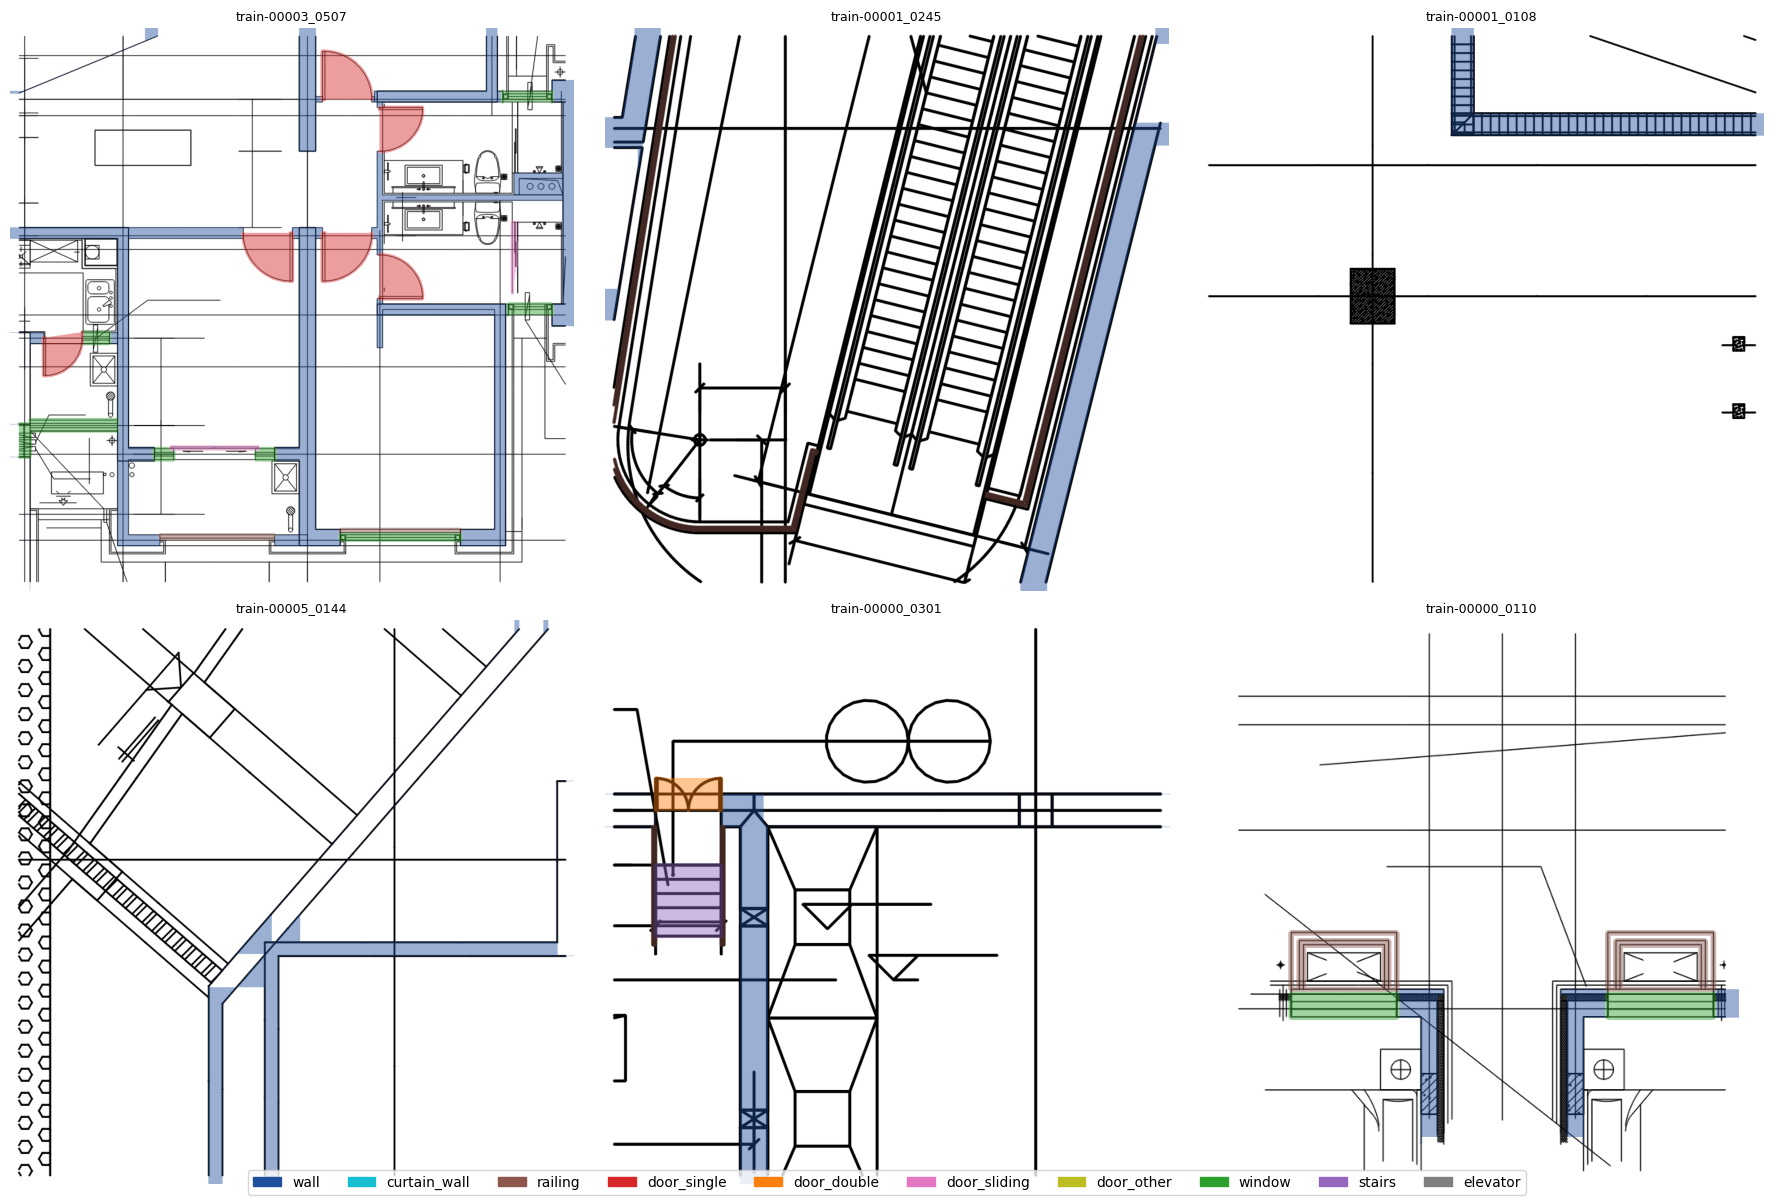

In [26]:
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
for ax, tid in zip(axes.ravel(), INDEX["train"].sample(6, random_state=1).id):
    img = R.cv2.imread(str(RENDER / "train" / f"{tid}_img.png"), 0)
    sem = R.cv2.imread(str(RENDER / "train" / f"{tid}_sem.png"), -1)
    ax.imshow(R.overlay(img, sem)[:, :, ::-1])
    ax.set_title(tid, fontsize=9)
    ax.axis("off")
handles = [plt.Rectangle((0, 0), 1, 1, color=R.PALETTE[i] / 255) for i in range(1, len(R.RASTER_CLASSES))]
fig.legend(handles, R.RASTER_CLASSES[1:], loc="lower center", ncol=10)
plt.tight_layout()
plt.show()

## 5. Class weights, datasets and loaders · ~20 s
**Class weights.** Wall pixels outnumber sliding-door pixels by roughly 100:1. Weights are `(median_freq / freq)^0.5`, clipped to [0.05, 10]. The square root keeps rare classes visible without making the model hallucinate them.

**Training sample**, step by step:
1. Load a full tile.
2. Scale by a factor in 0.8–1.25, to simulate drawings plotted at slightly different scales.
3. Take a 512² crop centred on a foreground pixel 80% of the time.
4. Random 90° rotation and flip.
5. Paint 3–18 random room names and dimensions (p 0.7). FloorPlanCAD tiles carry no text but real plans do.
6. Scan degradation (p 0.5): blur, fading, noise, dropouts and JPEG.
7. Inversion (p 0.15).
8. Input `x = (255 − img)/255`, i.e. ink = 1.

**Validation** uses full tiles (padded to 1024²) without augmentation.

class weights: {'background': np.float64(0.09), 'wall': np.float64(0.365), 'curtain_wall': np.float64(1.859), 'railing': np.float64(1.548), 'door_single': np.float64(0.861), 'door_double': np.float64(1.0), 'door_sliding': np.float64(2.646), 'door_other': np.float64(3.38), 'window': np.float64(1.135), 'stairs': np.float64(0.53), 'elevator': np.float64(0.799)}
train tiles 2887 -> 120 steps/epoch | val tiles 341


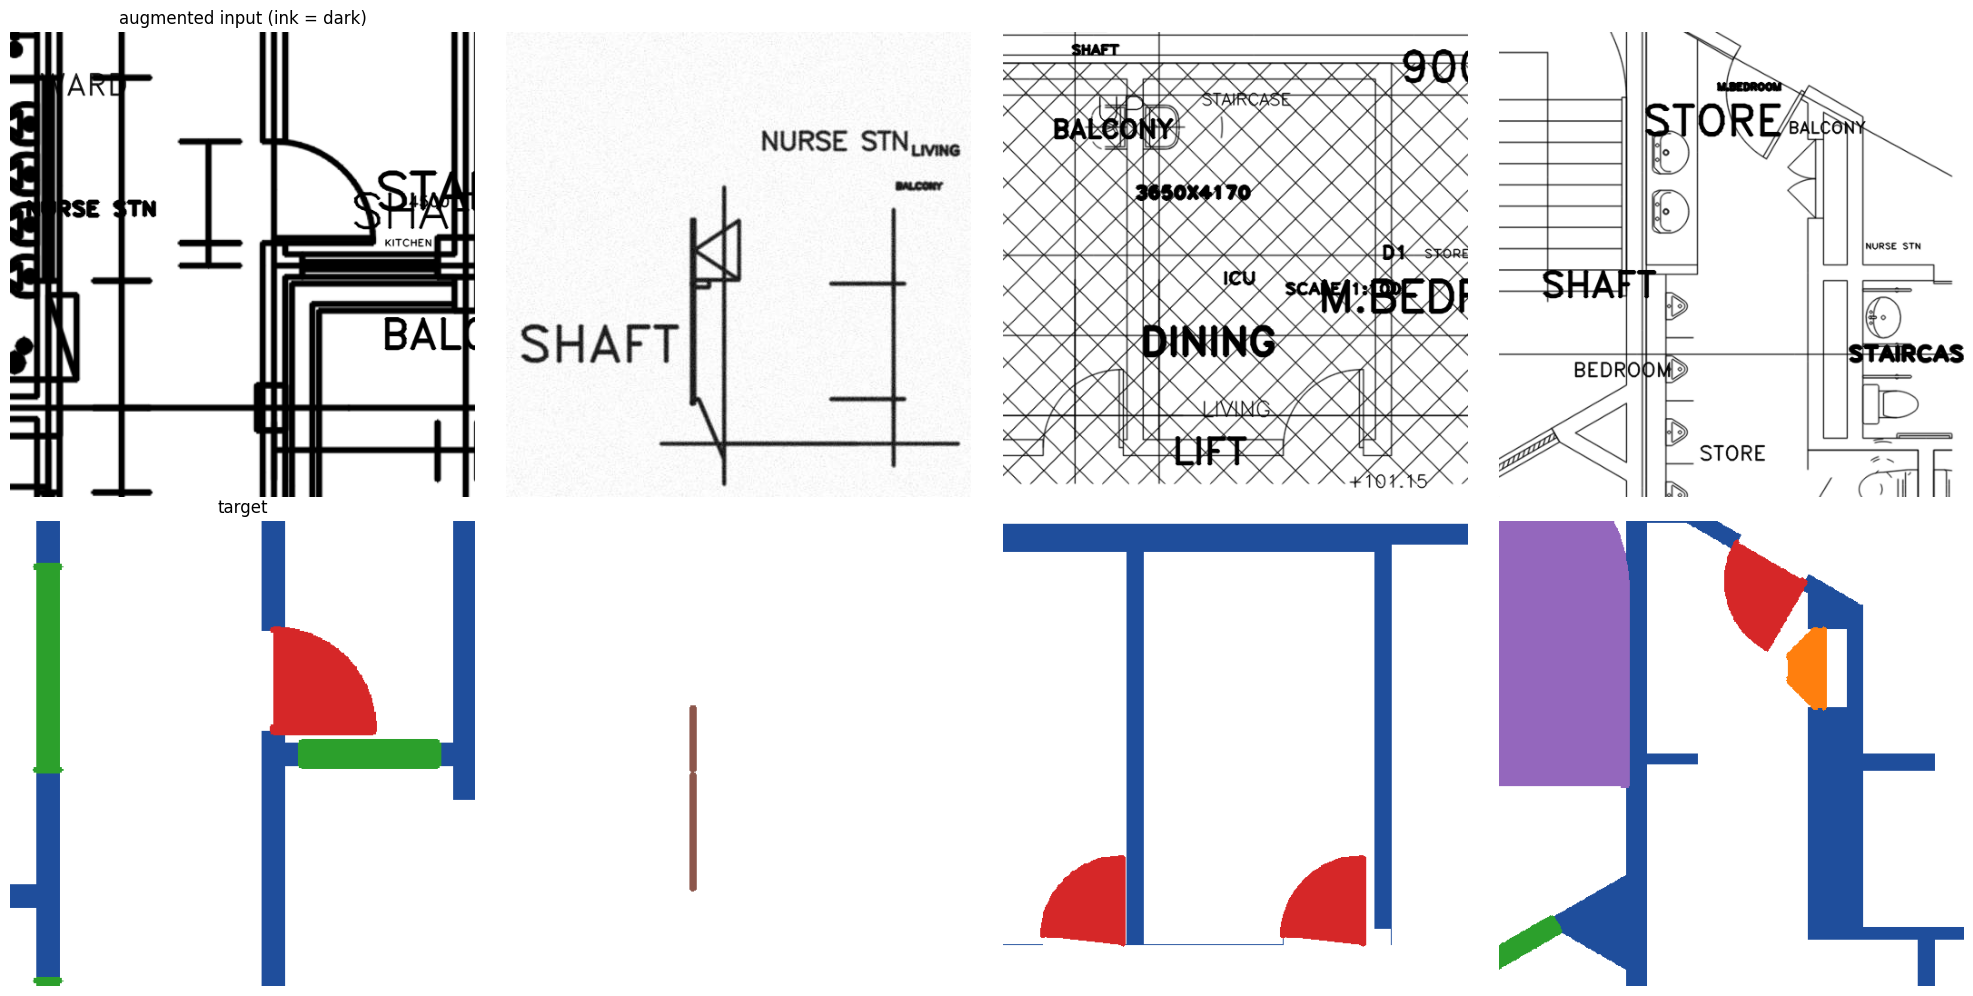

In [27]:
from torch.utils.data import DataLoader

W_CLASS, PX = R.class_weights(INDEX["train"])
print("class weights:", dict(zip(R.RASTER_CLASSES, np.round(W_CLASS, 3))))
train_ds = R.TileDataset(RENDER / "train", INDEX["train"].id.tolist(), crop=CROP, train=True, seed=SEED)
val_ds = R.TileDataset(RENDER / "val", INDEX["val"].id.tolist(), crop=1024, train=False)
train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=WORKERS, drop_last=True,
                          pin_memory=DEVICE == "cuda", persistent_workers=True, prefetch_factor=4)
val_loader = DataLoader(val_ds, batch_size=max(2, 4 * max(N_GPU, 1)), shuffle=False, num_workers=WORKERS)
print(f"train tiles {len(train_ds)} -> {len(train_loader)} steps/epoch | val tiles {len(val_ds)}")
xb, yb = next(iter(train_loader))
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
for k in range(4):
    axes[0, k].imshow(xb[k, 0], cmap="gray_r")
    axes[1, k].imshow(R.colorize(yb[k].numpy()))
    axes[0, k].axis("off")
    axes[1, k].axis("off")
axes[0, 0].set_title("augmented input (ink = dark)")
axes[1, 0].set_title("target")
plt.tight_layout()
plt.show()

## 6. Model + dry run · ~1–2 min
U-Net with a ResNet-34 encoder. The ImageNet RGB first convolution is collapsed to **1 input channel** (`in_channels=1`), and the head outputs 11 classes. Loss is weighted cross-entropy plus 0.5 × Dice over the 10 foreground classes, where the Dice term protects thin and rare classes.

The dry run does 25 real training steps on a throw-away copy of the model and reports **images/s**. From that it projects how many epochs `TRAIN_MINUTES` buys. If you see < 25 img/s on 2× T4, the loader is the bottleneck, which is CPU-bound with 4 Kaggle cores.

In [28]:
def dry_run(steps=25):
    m = R.make_model(ENCODER, ENCODER_WEIGHTS)
    net = torch.nn.DataParallel(m) if N_GPU > 1 else m
    net.to(DEVICE)
    opt = torch.optim.AdamW(m.parameters(), lr=BASE_LR)
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE == "cuda")
    lf = R.SegLoss(W_CLASS, device=DEVICE)
    def cycle(loader):
        while True:
            yield from loader
    it, n, t0 = cycle(train_loader), 0, None
    for s in range(steps):
        if s == 5:
            if DEVICE == "cuda":
                torch.cuda.synchronize()
            t0, n = time.time(), 0
        x, y = next(it)
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=DEVICE == "cuda"):
            loss = lf(net(x), y)
        opt.zero_grad()
        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()
        n += len(x)
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    ips = n / (time.time() - t0)
    mem = max((torch.cuda.max_memory_allocated(i) for i in range(N_GPU)), default=0) / 2**30
    del net, m, opt
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    return ips, mem

ips, mem = dry_run(8 if SMOKE else 25)
print(f"{ips:.1f} img/s | peak GPU mem {mem:.1f} GB | loss ok")
print(f"projected: {ips * TRAIN_MINUTES * 60 / max(len(train_ds), 1):.0f} epochs over {len(train_ds)} tiles in {TRAIN_MINUTES} min")

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

48.0 img/s | peak GPU mem 4.9 GB | loss ok
projected: 105 epochs over 2887 tiles in 105 min


## 7. Training · `TRAIN_MINUTES` (default 105 min)
Time-boxed training:
- AdamW at lr 3e-4, with a 3% warm-up then cosine decay down to 2%, all measured in **elapsed minutes**;
- mixed precision (fp16), gradient clipping at 5, `DataParallel` over both GPUs.

Every `VAL_EVERY_MIN` minutes it validates on full val tiles:
- `val_key_miou` is the mean IoU over **wall, single, double and sliding door, and window**, the classes the room and door pipeline relies on;
- the best checkpoint by that score goes to `ckpt/best.pt`;
- `ckpt/last.pt` is written after every validation round with optimiser state.

**If the cell is interrupted** (session hiccup), just re-run it: it resumes from `last.pt` and counts the minutes already spent. To train longer, raise `TRAIN_MINUTES` and re-run.

In [29]:
model = R.make_model(ENCODER, ENCODER_WEIGHTS)
loss_fn = R.SegLoss(W_CLASS, device=DEVICE)
history = R.train_timeboxed(model, train_loader, val_loader, loss_fn, minutes=TRAIN_MINUTES, ckpt_dir=CKPT,
                            base_lr=BASE_LR, device=DEVICE, val_every_min=VAL_EVERY_MIN,
                            resume=CKPT / "last.pt" if (CKPT / "last.pt").exists() else None)
json.dump(history, open(OUT / "history.json", "w"), indent=1)

{'epoch': 1, 'step': 120, 'minutes': 1.03, 'train_loss': 2.6564, 'lr': 9.700297363220699e-05}
{'epoch': 2, 'step': 240, 'minutes': 2.13, 'train_loss': 1.8116, 'lr': 0.00020250025817326138}
{'epoch': 3, 'step': 360, 'minutes': 3.24, 'train_loss': 1.4315, 'lr': 0.00029999949805490365}
{'epoch': 4, 'step': 480, 'minutes': 4.35, 'train_loss': 1.2906, 'lr': 0.00029990109436016393}
{'epoch': 5, 'step': 600, 'minutes': 5.43, 'train_loss': 1.1908, 'lr': 0.00029963847645282784}
{'epoch': 6, 'step': 720, 'minutes': 6.52, 'train_loss': 1.1355, 'lr': 0.0002992106993064849}
{'epoch': 7, 'step': 840, 'minutes': 7.62, 'train_loss': 1.1218, 'lr': 0.0002986118951051902}
{'epoch': 8, 'step': 960, 'minutes': 8.72, 'train_loss': 1.0463, 'lr': 0.00029784551741841517}
{'epoch': 9, 'step': 1080, 'minutes': 9.8, 'train_loss': 1.0186, 'lr': 0.0002969236940883739}
{'epoch': 10, 'step': 1099, 'minutes': 10.0, 'train_loss': 0.933, 'lr': 0.0002967346595075547, 'val_miou_fg': 0.3618, 'val_key_miou': 0.4567, 'saved'

**Learning curves · ~5 s.** Training loss should fall steadily and `val_key_miou` should still be rising slowly at the end; a plateau means extra minutes would not help much.

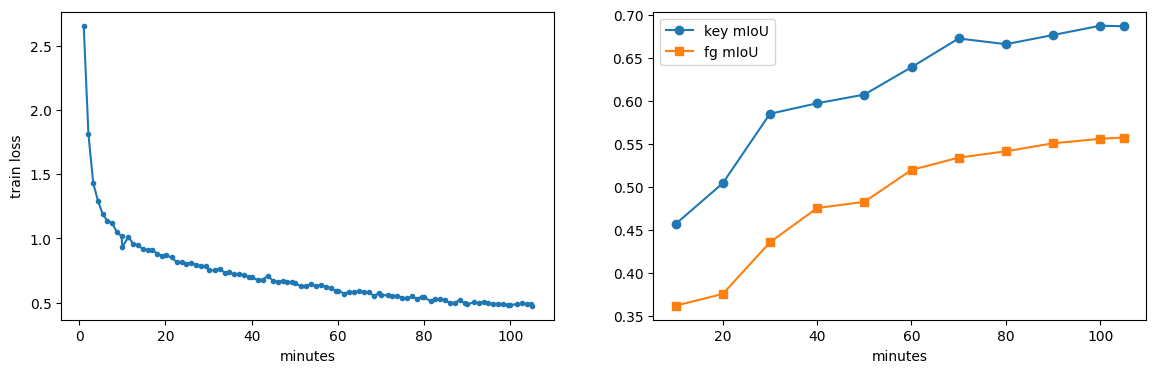

,epoch,step,minutes,train_loss,lr,val_miou_fg,val_key_miou,saved
91,92,10422,101.49,0.4861,0.000007,NaN,NaN,NaN
92,93,10542,102.61,0.4936,0.000006,NaN,NaN,NaN
93,94,10662,103.75,0.4860,0.000006,NaN,NaN,NaN
94,95,10782,104.88,0.4877,0.000006,NaN,NaN,NaN
95,96,10791,105.01,0.4757,0.000006,0.5574,0.6868,NaN


In [30]:
H = pd.DataFrame(json.load(open(OUT / "history.json")))
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(H.minutes, H.train_loss, ".-")
ax[0].set_xlabel("minutes")
ax[0].set_ylabel("train loss")
v = H.dropna(subset=["val_key_miou"]) if "val_key_miou" in H else H.iloc[:0]
ax[1].plot(v.minutes, v.val_key_miou, "o-", label="key mIoU")
ax[1].plot(v.minutes, v.val_miou_fg, "s-", label="fg mIoU")
ax[1].set_xlabel("minutes")
ax[1].legend()
plt.show()
display(H.tail(5))

## 8. Test evaluation · ~4–6 min (est.)
The best checkpoint is scored on the held-out FloorPlanCAD test tiles at three input qualities. `mild` and `heavy` use fixed, seeded degradations, so the numbers are reproducible:
- `clean`: the vector render, comparable to Track B's input;
- `mild`: a decent office scan;
- `heavy`: a poor photocopy, blurred, faded, noisy and JPEG-compressed.

Two metrics are reported:
- **Pixel IoU** per class, plus fg-mIoU over classes 1–10.
- **Panoptic Quality** for the instance classes. A predicted connected component matches a GT instance at IoU > 0.5. `PQ = SQ × RQ`: SQ is the mean IoU of matches, and RQ is an F1 of detection.

In [31]:
best = torch.load(CKPT / "best.pt", map_location="cpu", weights_only=False)
model = R.make_model(ENCODER, None)
model.load_state_dict(best["model"])
model.to(DEVICE).eval()
eval_net = torch.nn.DataParallel(model) if N_GPU > 1 else model
test_ids = INDEX["test"].id.tolist()
TEST = {}
t0 = time.time()
for level in ("clean", "mild", "heavy"):
    TEST[level] = R.evaluate_split(eval_net, RENDER / "test", test_ids, DEVICE, level, batch=4 * max(N_GPU, 1))
    print(f"{level}: fg-mIoU {TEST[level]['miou_fg']:.4f} | key mIoU {TEST[level]['key_miou']:.4f} | {time.time() - t0:.0f}s")
iou_table = pd.DataFrame({lv: TEST[lv]["iou"] for lv in TEST}).drop(index="background")
display(iou_table.style.format("{:.3f}").background_gradient(cmap="Greens", vmin=0, vmax=1))
pq_table = pd.concat({lv: TEST[lv]["pq"].set_index("class")[["PQ", "SQ", "RQ", "tp", "fp", "fn"]] for lv in TEST}, axis=1)
display(pq_table)

clean: fg-mIoU 0.5098 | key mIoU 0.6379 | 171s
mild: fg-mIoU 0.5090 | key mIoU 0.6359 | 369s
heavy: fg-mIoU 0.5043 | key mIoU 0.6310 | 574s


,clean,mild,heavy
wall,0.504,0.502,0.498
curtain_wall,0.248,0.249,0.247
railing,0.080,0.079,0.076
door_single,0.791,0.790,0.786
door_double,0.785,0.784,0.779
door_sliding,0.633,0.630,0.623
door_other,0.074,0.078,0.067
window,0.476,0.474,0.469
stairs,0.685,0.683,0.681
elevator,0.821,0.822,0.818


clean                                     mild                  \
                  PQ      SQ      RQ    tp    fp   fn      PQ      SQ      RQ   
class                                                                           
door_double   0.6985  0.8506  0.8211   599   227   34  0.7001  0.8484  0.8252   
window        0.3748  0.8090  0.4633   790  1371  459  0.3681  0.8035  0.4582   
elevator      0.6639  0.9292  0.7145   219   172    3  0.6735  0.9288  0.7252   
stairs        0.2581  0.8629  0.2991   147   633   56  0.2599  0.8618  0.3015   
door_sliding  0.5936  0.8304  0.7148   183   128   18  0.5803  0.8247  0.7036   
door_single   0.6955  0.8783  0.7918  1295   518  163  0.6889  0.8797  0.7832   
door_other    0.0000  0.0000  0.0000     0   262   16  0.0000  0.0000  0.0000   

                                heavy                                   
                tp    fp   fn      PQ      SQ      RQ    tp    fp   fn  
class                                                                   
door_double    602   224   31  0.6821  0.8450  0.8073   601   255   32  
window         789  1406  460  0.3537  0.8030  0.4404   780  1513  469  
elevator       219   163    3  0.6569  0.9254  0.7099   219   176    3  
stairs         147   625   56  0.2542  0.8576  0.2964   147   642   56  
door_sliding   184   138   17  0.5622  0.8173  0.6879   184   150   17  
door_single   1284   537  174  0.6778  0.8799  0.7704  1263   558  195  
door_other       0   246   16  0.0000  0.0000  0.0000     0   264   16

**Qualitative check · ~15 s.** Columns show input (mild degradation), ground truth and prediction.

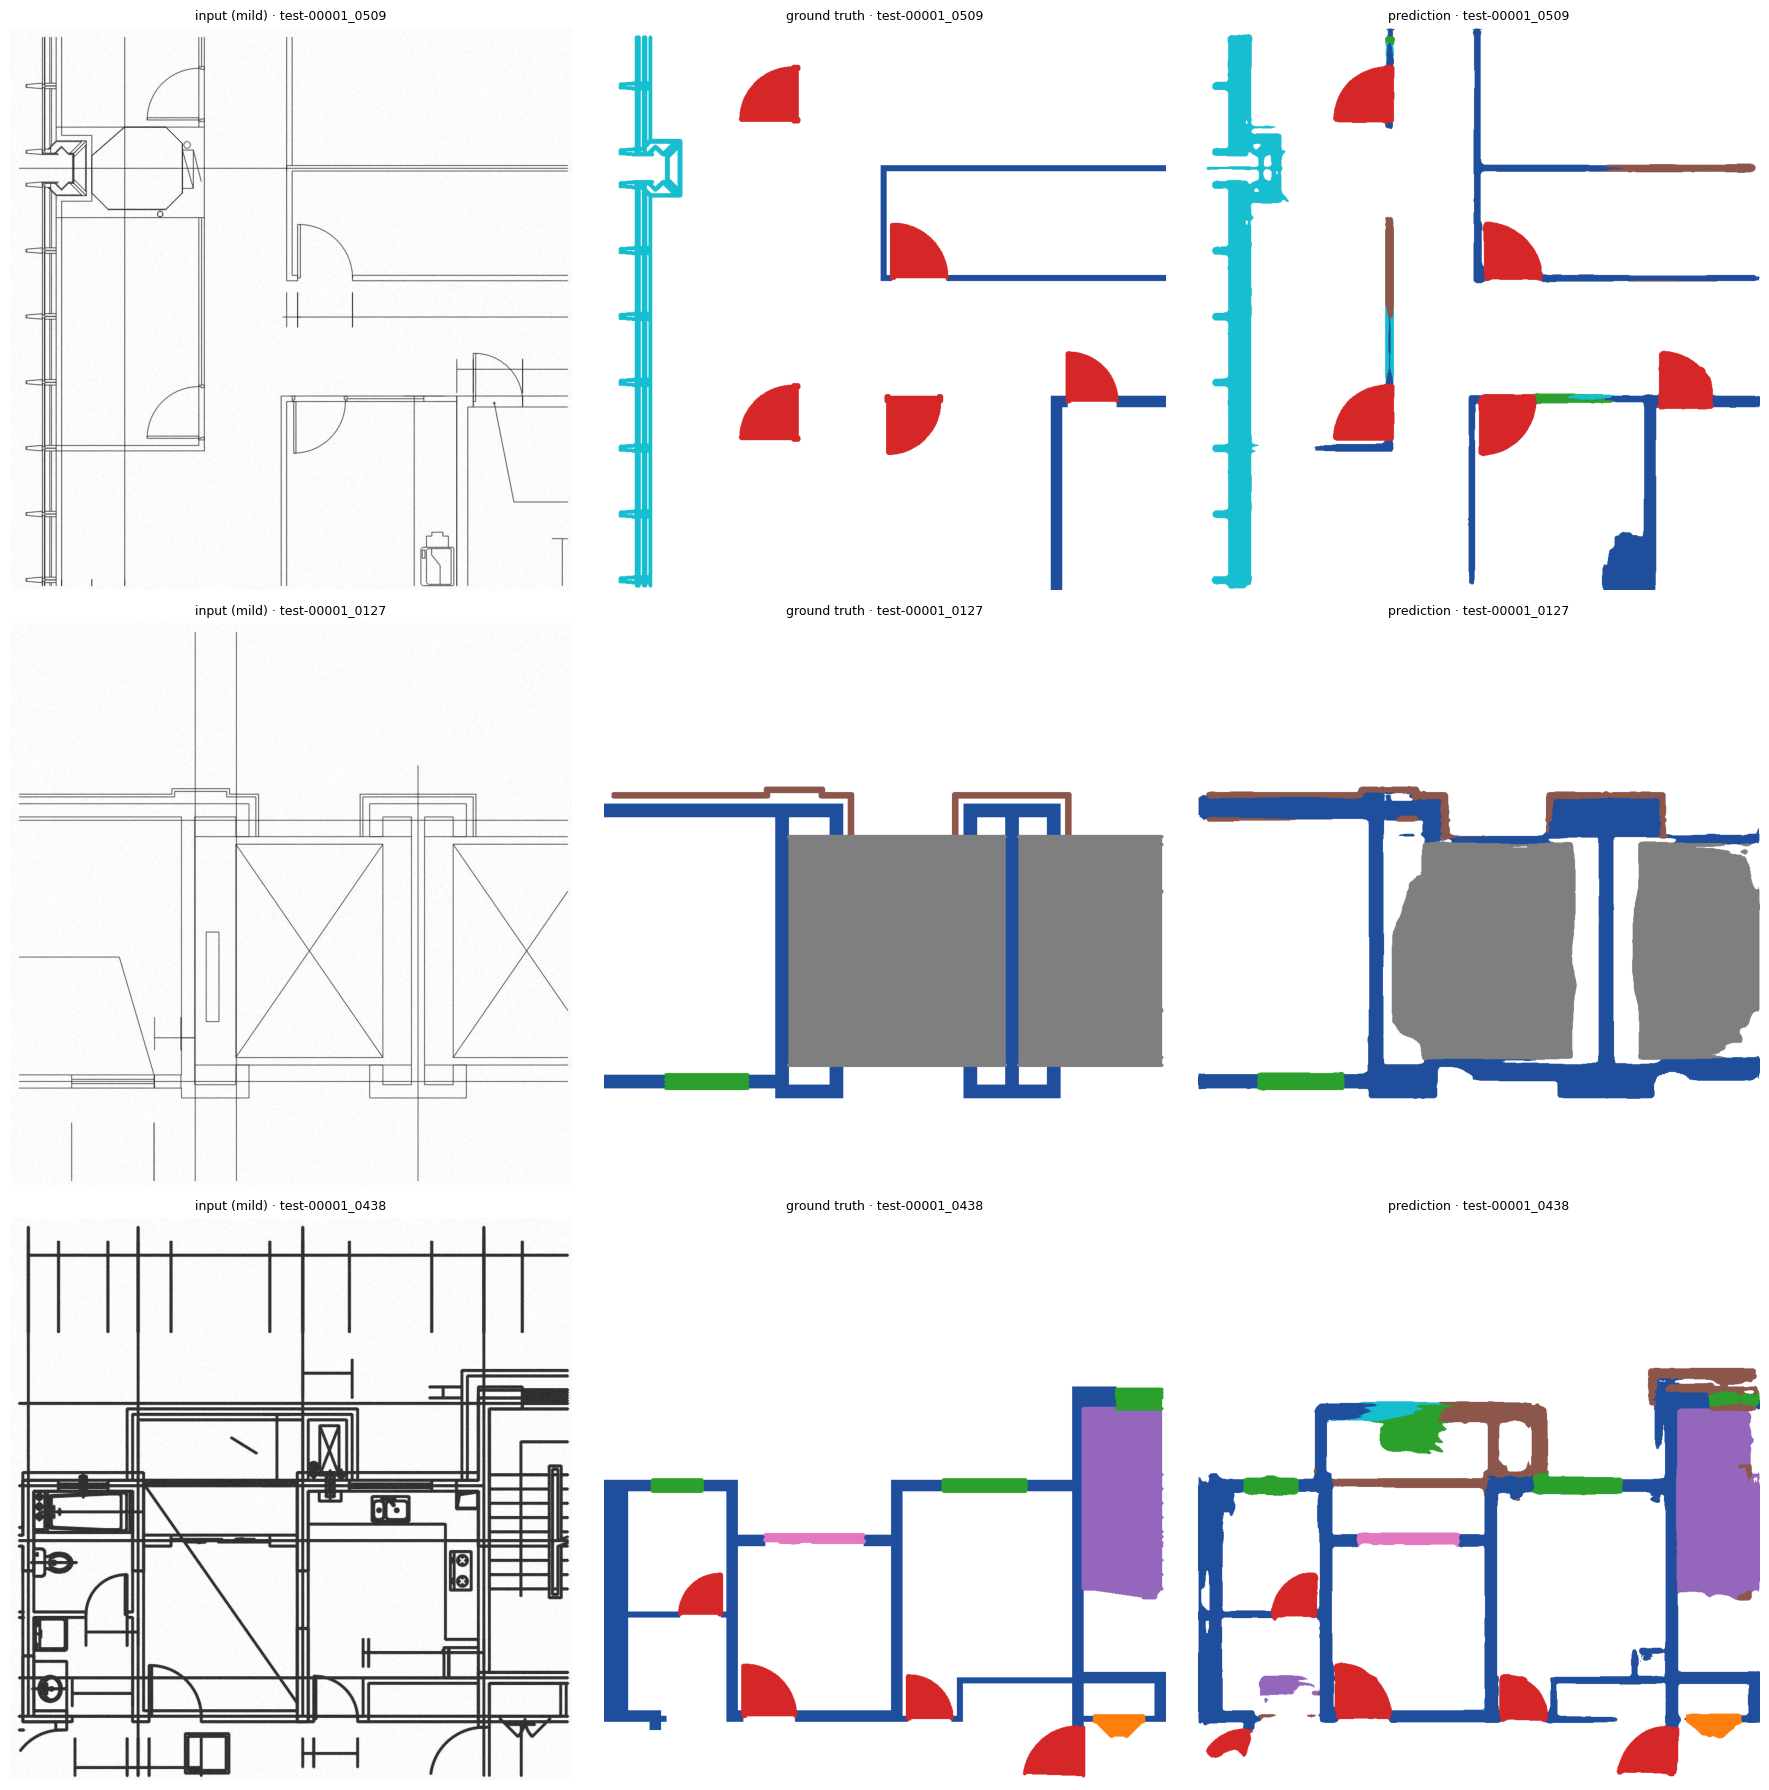

In [32]:
fig, axes = plt.subplots(3, 3, figsize=(18, 18))
for row, tid in zip(axes, INDEX["test"].sample(3, random_state=3).id):
    img, sem, _ = R.load_tile(RENDER / "test", tid)
    img = R.degrade_fixed(img, "mild", 0)
    pred, _ = R.predict_image(model, img, DEVICE, tile=1024, overlap=0)
    for ax, im, t in zip(row, [img, R.colorize(sem), R.colorize(pred)], ["input (mild)", "ground truth", "prediction"]):
        ax.imshow(im, cmap="gray" if im.ndim == 2 else None)
        ax.set_title(f"{t} · {tid}", fontsize=9)
        ax.axis("off")
plt.tight_layout()
plt.show()

## 9. TOWER-B: pixels → walls, rooms, doors, adjacency → compare with Track A · ~4–6 min (est.)
This is the real test: an **Indian** hospital/residential drawing the model has never seen, drafted in a different style from FloorPlanCAD. The steps:

1. **Find inputs**: the DXF and the Track A manifest (`manifest_TOWER-B_GF.json`). The search covers the working dir, `/kaggle/input`, then `towerb/` in the HF repo.
2. **Region**: the bounding box of Track A's rooms + 3 m. TOWER-B's DXF is a whole-site plan, and this crops it to the building so both tracks see the same area.
3. **Render** every visible entity at 10 mm/px, *including text*. The DXF is used only as a picture: layers, blocks and attributes are thrown away.
4. **Sliding-window inference**: 1024² windows with 128 px overlap and a Hanning blend, giving class and confidence per pixel.
5. **Structure extraction**, step by step:
   - **Seal walls.** Boundary = wall, curtain wall, railing, sliding door and window pixels, with 40 mm gaps closed. A door is a hole in the wall band, so the band is bridged by 2.6 m horizontal and vertical closings, kept only within 150 mm of a predicted swing door.
   - **Rooms.** Connected components of free space. Components touching the border are the exterior. Rooms < 0.5 m² are dropped. The door-gap pixels are then given back to the nearest room. Large open areas outside the sealed rooms (verandas, lobbies) are added as `open` pockets with a 2 m closing.
   - **Openings.** Connected components of door and window pixels: majority class, width = long side of the minimum-area rectangle, and the two rooms (or `EXTERIOR`) they touch.
   - **Adjacency.** Two rooms are adjacent if their boundaries come within 350 mm (one wall) along ≥ 300 mm, or if a door connects them.
6. **Compare with Track A.**
   - Rooms are matched one-to-one by **Hungarian assignment on polygon IoU (≥ 0.5)**.
   - Doors are matched by position (≤ 1 m), and widths are compared.
   - Adjacency is scored as edge **precision/recall/F1** on the matched rooms only.

**Ceiling measured in development:** the same post-processing fed with *perfect* masks (rendered from the auto-labelled TOWER-B SVG) reached
- rooms: 114 / 200 matched, mean IoU 0.90, median signed area error −2%;
- doors: 162 / 164 matched, median width error 60 mm;
- adjacency F1: wall 0.94, door 0.93.

Most unmatched Track A rooms are **tag-split** spaces (one open area that Track A divides using room tags) or **open** spaces without enclosing walls. Pixels alone cannot recover them, which is a real, reportable difference between the tracks. The model's numbers below should be read against this ceiling.

In [33]:
def find_input(pattern, hf_name=None):
    for root in (Path("."), WORK, DATA / "towerb", Path("/kaggle/input")):
        hits = sorted(root.rglob(pattern)) if root.exists() else []
        if hits:
            return hits[0]
    if hf_name and not LOCAL_HF_DIR:
        from huggingface_hub import hf_hub_download
        try:
            return Path(hf_hub_download(HF_REPO_ID, f"towerb/{hf_name}", repo_type="dataset", local_dir=str(DATA), token=HF_TOKEN))
        except Exception as e:
            print("HF fallback failed:", type(e).__name__)
    return None

import gc
train_loader = val_loader = None
gc.collect()
DXF_PATH = find_input("*TOWER-B*.dxf", "TOWER-B GF(1).dxf")
MANIFEST_PATH = find_input("manifest_TOWER-B*.json", "manifest_TOWER-B_GF.json")
print("DXF:", DXF_PATH, "\nTrack A manifest:", MANIFEST_PATH)
assert DXF_PATH and MANIFEST_PATH, "attach the TOWER-B DXF and Track A manifest (see the intro)"
MAN_A = json.load(open(MANIFEST_PATH))
REGION = R.manifest_region(MAN_A)
t0 = time.time()
TB_IMG, TB_META = R.render_dxf(DXF_PATH, REGION, MM_PER_PX)
print(TB_META, f"| {time.time() - t0:.0f}s")

DXF: /kaggle/input/datasets/savageshambhu/track-c-dataset/TOWER-B GF(1).dxf 
Track A manifest: /kaggle/input/datasets/savageshambhu/track-c-dataset/manifest_TOWER-B_GF.json


copy process ignored ACAD_PROXY_OBJECT(#123259) - this may cause problems in AutoCAD
copy process ignored ACAD_PROXY_OBJECT(#123268) - this may cause problems in AutoCAD
copy process ignored ACAD_PROXY_OBJECT(#123277) - this may cause problems in AutoCAD
copy process ignored ACAD_PROXY_OBJECT(#1232A0) - this may cause problems in AutoCAD
copy process ignored ACAD_PROXY_OBJECT(#1232D6) - this may cause problems in AutoCAD
copy process ignored ACAD_PROXY_OBJECT(#1232E5) - this may cause problems in AutoCAD
copy process ignored ACAD_PROXY_OBJECT(#1232F4) - this may cause problems in AutoCAD
copy process ignored ACAD_PROXY_OBJECT(#123310) - this may cause problems in AutoCAD
copy process ignored ACAD_PROXY_OBJECT(#12332C) - this may cause problems in AutoCAD
copy process ignored ACAD_PROXY_OBJECT(#123361) - this may cause problems in AutoCAD
copy process ignored ACAD_PROXY_OBJECT(#123370) - this may cause problems in AutoCAD
copy process ignored ACAD_PROXY_OBJECT(#12337F) - this may cause 

{'region_mm': [np.float64(718896.8), np.float64(-26602.6), np.float64(801103.7), np.float64(75588.5)], 'mm_per_px': 10.0, 'size_px': [8221, 10220], 'n_polylines': 29141, 'n_text': 1584} | 24s


**Inference · ~1–2 min on a T4 (est.).** The output is a class map and a confidence map at full drawing size.

In [34]:
t0 = time.time()
TB_PRED, TB_CONF = R.predict_image(model, TB_IMG, DEVICE, tile=1024, overlap=128, batch=8 if DEVICE == "cuda" else 2)
counts = np.bincount(TB_PRED.ravel(), minlength=len(R.RASTER_CLASSES))
print(f"{time.time() - t0:.0f}s |", {c: int(n) for c, n in zip(R.RASTER_CLASSES, counts) if n})

240s | {'background': 74872316, 'wall': 5175653, 'curtain_wall': 45775, 'railing': 338356, 'door_single': 856258, 'door_double': 342663, 'door_sliding': 81784, 'door_other': 12297, 'window': 681135, 'stairs': 1397437, 'elevator': 214946}


**Structure extraction + comparison · ~1–2 min (measured ~80 s on CPU with GT masks).**

In [35]:
STRUCT = R.extract_structure(TB_PRED, TB_CONF, REGION, MM_PER_PX)
CMP = R.compare_with_track_a(MAN_A, STRUCT["rooms"], STRUCT["room_lab"], STRUCT["openings"], STRUCT["adjacency"], REGION, MM_PER_PX)
print(f"extracted {len(STRUCT['rooms'])} rooms, {sum(o['kind'] == 'door' for o in STRUCT['openings'])} doors, "
      f"{sum(o['kind'] == 'window' for o in STRUCT['openings'])} windows, {len(STRUCT['adjacency'])} adjacency edges in {STRUCT['seconds']}s")
ceiling = {"rooms": {"matched_iou50": 114, "mean_iou_matched": 0.898}, "doors": {"matched_within_1m": 162, "width_median_abs_err_mm": 60.0},
           "adjacency_wall": {"f1": 0.937}, "adjacency_door": {"f1": 0.926}}
rows = []
for sec, d in CMP.items():
    for k, v in d.items():
        rows.append({"section": sec, "metric": k, "Track C (model)": v, "ceiling (GT masks)": ceiling.get(sec, {}).get(k, "")})
display(pd.DataFrame(rows))

extracted 218 rooms, 154 doors, 126 windows, 497 adjacency edges in 65.2s


,section,metric,Track C (model),ceiling (GT masks)
0,rooms,gt_rooms,200.0000,
1,rooms,pred_rooms,218.0000,
2,rooms,matched_iou50,137.0000,114
3,rooms,recall,0.6850,
4,rooms,precision,0.6284,
5,rooms,mean_iou_matched,0.8632,0.898
6,rooms,median_area_error_pct,9.9900,
7,doors,gt_doors,164.0000,
8,doors,pred_doors,154.0000,
9,doors,matched_within_1m,133.0000,162


**Overlays · ~20 s.** Left: the whole building with predicted classes and rooms tinted. Right: a 30 m × 30 m zoom around the densest door cluster.

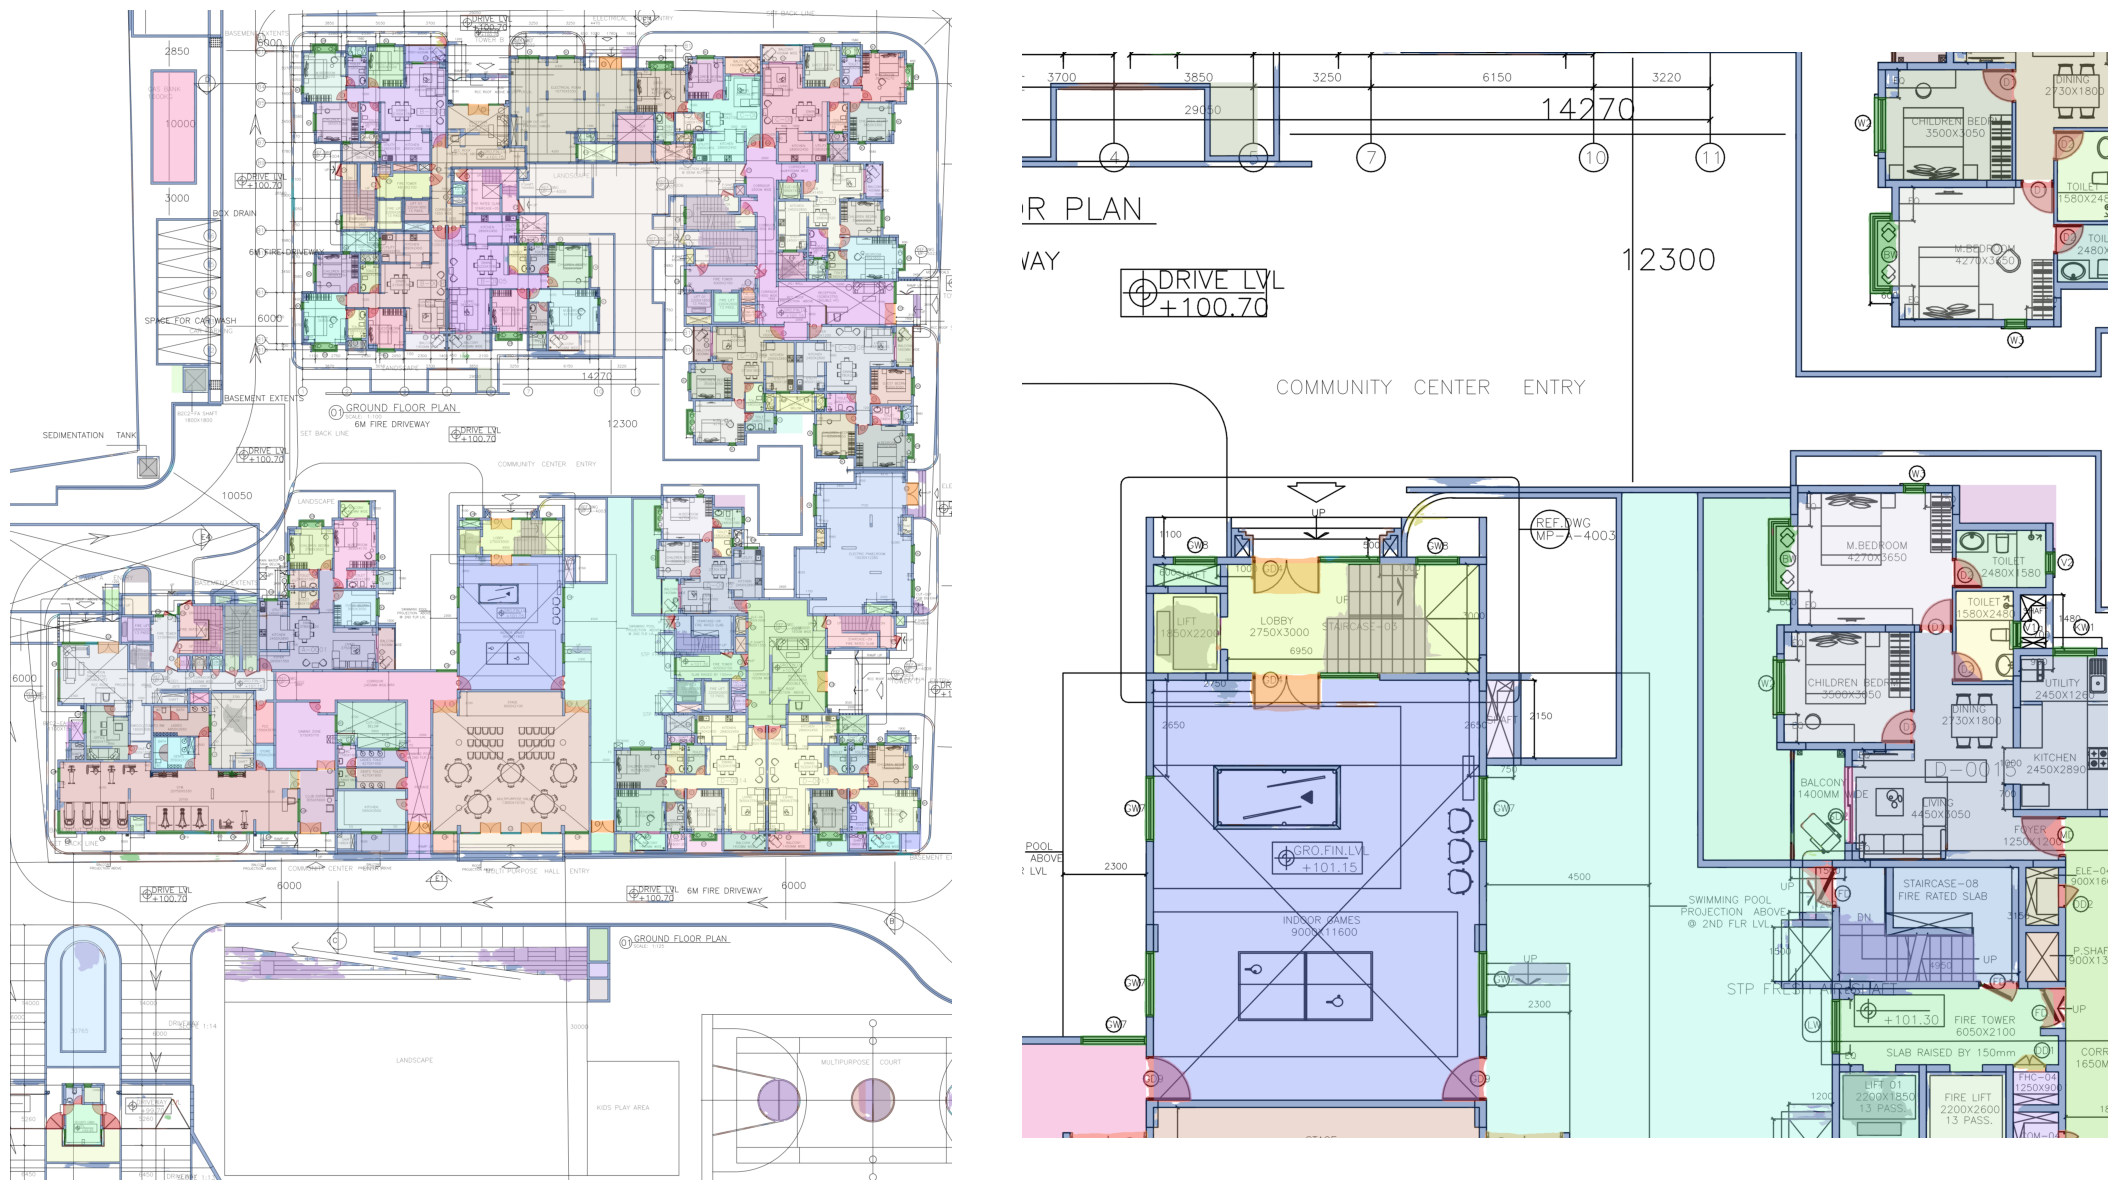

In [36]:
OV = R.overlay(TB_IMG, TB_PRED, STRUCT["rooms"], STRUCT["room_lab"])
doors = np.array([R.mm_to_px(np.array([o["position"]]), REGION, MM_PER_PX)[0] for o in STRUCT["openings"] if o["kind"] == "door"])
cx, cy = (np.median(doors, 0).astype(int) if len(doors) else (OV.shape[1] // 2, OV.shape[0] // 2))
h = 1500
zoom = OV[max(0, cy - h):cy + h, max(0, cx - h):cx + h]
fig, ax = plt.subplots(1, 2, figsize=(22, 12))
ax[0].imshow(R.cv2.resize(OV, None, fx=0.25, fy=0.25, interpolation=R.cv2.INTER_AREA)[:, :, ::-1])
ax[1].imshow(zoom[:, :, ::-1])
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()
R.cv2.imwrite(str(OUT / "towerb_overlay_quarter.png"), R.cv2.resize(OV, None, fx=0.25, fy=0.25, interpolation=R.cv2.INTER_AREA))
_ = R.cv2.imwrite(str(OUT / "towerb_overlay_zoom.png"), zoom)

## 10. Optional: OCR room labels · ~3–6 min (est.)
This closes the loop to "rooms with names", which compliance rules need (a *toilet* must be ≥ x m², an *OT* needs y).
1. The building is re-rendered at 5 mm/px so 150–250 mm text is 30–50 px tall.
2. EasyOCR reads each predicted room's bounding box.
3. The words become `ocr_text`.

Agreement is the share of matched rooms whose Track A label appears in the OCR text. Set `RUN_OCR=False` to skip.

In [37]:
if RUN_OCR:
    %pip install -q easyocr
    t0 = time.time()
    R.ocr_room_labels(DXF_PATH, REGION, STRUCT["rooms"], MM_PER_PX, gpu=DEVICE == "cuda")
    OCR = R.label_agreement(STRUCT["rooms"])
    print(OCR, f"| {time.time() - t0:.0f}s")
    display(pd.DataFrame([{k: r.get(k) for k in ("id", "area_m2", "enclosure", "track_a_label", "ocr_text")} for r in STRUCT["rooms"]]).head(25))
else:
    OCR = None

Note: you may need to restart the kernel to use updated packages.


copy process ignored ACAD_PROXY_OBJECT(#123259) - this may cause problems in AutoCAD
copy process ignored ACAD_PROXY_OBJECT(#123268) - this may cause problems in AutoCAD
copy process ignored ACAD_PROXY_OBJECT(#123277) - this may cause problems in AutoCAD
copy process ignored ACAD_PROXY_OBJECT(#1232A0) - this may cause problems in AutoCAD
copy process ignored ACAD_PROXY_OBJECT(#1232D6) - this may cause problems in AutoCAD
copy process ignored ACAD_PROXY_OBJECT(#1232E5) - this may cause problems in AutoCAD
copy process ignored ACAD_PROXY_OBJECT(#1232F4) - this may cause problems in AutoCAD
copy process ignored ACAD_PROXY_OBJECT(#123310) - this may cause problems in AutoCAD
copy process ignored ACAD_PROXY_OBJECT(#12332C) - this may cause problems in AutoCAD
copy process ignored ACAD_PROXY_OBJECT(#123361) - this may cause problems in AutoCAD
copy process ignored ACAD_PROXY_OBJECT(#123370) - this may cause problems in AutoCAD
copy process ignored ACAD_PROXY_OBJECT(#12337F) - this may cause 

{'rooms_with_track_a_label': 132, 'ocr_contains_label': 62, 'rate': 0.4697} | 85s


,id,area_m2,enclosure,track_a_label,ocr_text
0,P001,4.569,closed,BALCONY,BALCONY WIDE 15 40OMM SD1
1,P002,5.229,closed,BALCONY,BALCONY 1500 140OMM WSDE SD1
2,P003,1.068,closed,SHAFT,HAFT
3,P004,1.077,closed,SHAFT,SHAFT
4,P005,10.241,closed,GUEST BEDRM,EQ GHEST BBEDRH 3o50x35oo D
5,P006,10.224,closed,GUEST BEDRM,GUEST BHDRM 5050x/3500 D
6,P007,15.791,closed,M.BEDROOM,M.BEDROOM 36508X4270 D
7,P008,14.881,closed,M.BEDROOM,EQ M.BEDROOM 3650x/270
8,P009,3.665,closed,TOILET,TOILET 1580x248
9,P010,3.672,closed,TOILET,TOILET 1580x248


## 11. Save the Track C manifest and push to Hugging Face · ~1 min
Outputs:
- `towerb_trackC_manifest.json`: rooms (polygons in the **same mm frame as Track A**), openings with widths and connections, and adjacency with shared wall length and door/window counts;
- `towerb_vs_trackA.json` and `test_metrics.json`;
- `best.pt` (~100 MB) plus the overlays.

Everything goes to `models/raster/` in your **private** dataset repo. The rendered FloorPlanCAD images are **not** uploaded (CC BY-NC).

In [38]:
model_info = {"arch": f"Unet-{ENCODER}", "train_minutes": TRAIN_MINUTES, "val": best.get("val", {}).get("key_miou"),
              "classes": R.RASTER_CLASSES, "mm_per_px": MM_PER_PX}
manifest_c = R.to_manifest(STRUCT, REGION, MM_PER_PX, Path(DXF_PATH).name, model_info)
json.dump(manifest_c, open(OUT / "towerb_trackC_manifest.json", "w"), indent=1)
json.dump({**CMP, "ocr": OCR}, open(OUT / "towerb_vs_trackA.json", "w"), indent=1)
json.dump({lv: {k: (v.to_dict("records") if isinstance(v, pd.DataFrame) else v) for k, v in d.items()} for lv, d in TEST.items()},
          open(OUT / "test_metrics.json", "w"), indent=1)
shutil.copy(CKPT / "best.pt", OUT / "best.pt")
print(sorted(p.name for p in OUT.iterdir()))
if not SMOKE and HF_TOKEN:
    HfApi().upload_folder(folder_path=str(OUT), path_in_repo=HF_PUSH_PREFIX, repo_id=HF_REPO_ID, repo_type="dataset",
                          token=HF_TOKEN, commit_message=f"Track C raster U-Net ({TRAIN_MINUTES} min) + TOWER-B results")
    print(f"pushed to {HF_REPO_ID}/{HF_PUSH_PREFIX}")

['best.pt', 'history.json', 'test_metrics.json', 'towerb_overlay_quarter.png', 'towerb_overlay_zoom.png', 'towerb_trackC_manifest.json', 'towerb_vs_trackA.json']
pushed to saiashish29/FloorPlanCAD/models/raster


## What to report
| Question | Where |
|---|---|
| How good is the pixel segmentation? | §8 IoU table (clean/mild/heavy) |
| Does it find individual doors and windows? | §8 PQ table |
| How robust is it to scan quality? | the drop from clean → heavy |
| Does it rebuild the same rooms as Track A? | §9 rooms: recall, mean IoU, area error |
| Same doors, same widths? | §9 doors: recall, width error |
| Same room graph? | §9 adjacency F1 (wall and door edges) |
| How much is the model vs. the post-processing? | §9 model column vs. the ceiling column |

For the three-way table, put Track A (= 1.0 by definition), Track B (GNN, after Phase C/D) and Track C side by side on the TOWER-B rows. The raster track's selling point is the input: it needs **only an image**, so it also applies to scanned or PDF-only plans where neither Track A nor Track B can run.